> ## 🎤 강사 스크립트 · 이 강사용 노트북 사용법
>
> 이 노트북은 **학생용 실습 노트북 `D6_ASR원리_실습.ipynb`의 모든 셀을 그대로 담고**, 그 사이사이에 이렇게 **인용 블록(왼쪽 세로줄)으로 된 🎤 강사 스크립트 셀**을 끼워 넣은 것입니다. 수업 화면에는 학생용 노트북을 띄우고, 이 노트북은 강사 화면(또는 태블릿)에 열어 두고 읽으며 진행하세요.
>
> | 표시 | 뜻 |
> |---|---|
> | 🎯 | 이 블록에서 학생이 가져가야 할 한 가지 |
> | 🗣️ | 그대로 읽어도 되는 강사 멘트 (따옴표 안) |
> | 🍎 | 어려운 개념을 일상 비유로 바꾼 설명 |
> | 🖥️ | 화면 시연: 셀 실행, 애니메이션 조작 |
> | ❓ | 학생에게 던지는 질문 → 예상 답 |
> | 🆘 | 빈칸 실습에서 막힌 학생에게 단계별로 주는 힌트 |
> | ⚠️ | 자주 막히는 지점, 오개념, 오류 |
> | ➡️ | 다음 블록으로 넘어가는 연결 멘트 |
>
> **오늘의 난이도 경고**: D6은 이 과정에서 **수식이 가장 많은 날**입니다. CTC의 경로 합, α 점화식, attention, Transducer 격자, InfoNCE가 한꺼번에 나옵니다. 그래서 이 스크립트는 **"받아쓰기 시험" 비유 하나로 하루 전체를 꿰도록** 짜여 있고, 수식마다 **"작은 예로 직접 세어 보기 → 공식 → 코드로 같은지 확인"** 의 순서를 지킵니다.
>
> > 🍎 **하루를 꿰는 비유**: 녹음 = 빠르게 말하는 받아쓰기 문제, 프레임 = 0.02초마다 찍는 연속 사진, 정렬 = "몇 번째 사진이 어느 글자인가" (채점표에는 없음), CTC = 사진마다 글자나 '없음'을 적고 나중에 겹친 것을 지우기, AED = 전체를 다 듣고 한 글자씩 받아 적기, Transducer = 들으면서 받아 적되 앞에 쓴 글자를 보며 고치기, 자기지도 학습 = 받아쓰기 전에 귀부터 트이게 하는 '빈칸 듣기' 연습.
>
> > 💡 학생 노트북에 없는 내용(정답, 예상 출력, 힌트)은 이 강사용 노트북에만 있습니다. **학생에게는 이 파일을 배포하지 마세요.**

> ## 🎤 강사 스크립트 · 하루 시간표와 수업 전 점검
>
> #### 하루 시간표 (50분 수업 + 10분 휴식 × 4)
>
> | 시간 | 교시 | 노트북 | 빈칸 | 애니메이션 | 슬라이드 |
> |---|---|---|---|---|---|
> | 0:00–0:50 | 1교시 | 도입, Part 0 (모델 미리 받기), Part 1 정렬 문제, Part 2 CTC 접기 · 경로 수 · α | 1 · 2 | D6-1 ~ D6-4 | p.1 ~ 7 |
> | 1:00–1:50 | 2교시 | Part 3 Wav2Vec2 프레임 수 · greedy 디코딩 · 스파이크 · 타임스탬프 | 3 · 4 · 5 | D6-5 | p.8 ~ 10 |
> | 2:00–2:50 | 3교시 | Part 4 attention · Whisper 루프, Part 5 Transducer · 비교 | 6 · 7 · 8 | D6-6 ~ D6-8 | p.11 ~ 15 |
> | 3:00–3:50 | 4교시 | Part 6 wav2vec 2.0 · HuBERT, Part 7 정리 · 제출 | 9 | D6-9 | p.16 ~ 20 |
>
> **진도가 밀릴 때 줄이는 순서** (빈칸 실습과 워크시트는 줄이지 않습니다)
> 1. Part 2-2의 "실제 크기" 경로 수 계산 → 숫자만 말로
> 2. 수식 검증 3 (torchaudio rnnt_loss) → 건너뛰기 (빈칸 8의 '전부 더하기' 비교로 충분)
> 3. 6-3 wav2vec2-base 사전학습 모델 셀 → 강사 화면 시연만 (학생은 실행하지 않아도 됨)
>
> #### 수업 15분 전 점검
> - [ ] Colab에서 이 노트북을 **위에서부터 끝까지 한 번 실행**합니다. 모델 4개(wav2vec2-base-960h 약 360 MB, whisper-tiny 약 150 MB, wav2vec2-base 약 380 MB, hubert-base-ls960 약 360 MB)가 캐시에 받아집니다. 전체 실행 GPU 3~5분, CPU 8~12분.
> - [ ] gTTS는 **인터넷이 필요**합니다. 학원 망에서 막히면 미리 만든 `en.mp3`를 공유 드라이브에 올려 두고 `y_en = librosa.load("en.mp3", sr=16000)[0]`로 바꿔 쓰게 합니다.
> - [ ] [animation.html](https://imguru-mooc.github.io/AI_Voice/day06/animation.html), [worksheet.html](https://imguru-mooc.github.io/AI_Voice/day06/worksheet.html) 탭을 열어 둡니다.
> - [ ] 학생 안내문 붙여 넣기:
>
> ```
> D6 실습 노트북: (Colab 링크) → [파일] → [Drive에 사본 저장]
> 권장: [런타임] → [런타임 유형 변경] → T4 GPU (CPU도 됩니다)
> Part 0 셀 3개를 먼저 실행하고, 이어서 Part 3의 첫 셀(Wav2Vec2 불러오기)도 실행해 두세요 (모델 다운로드)
> 워크시트: https://imguru-mooc.github.io/AI_Voice/day06/worksheet.html
> ```
>
> #### 오늘 학생들이 가장 많이 막히는 곳 (미리 알고 들어가기)
> | 위치 | 증상 | 대응 |
> |---|---|---|
> | 빈칸 2 | 'cat'은 맞는데 'baa'에서 ❌ | 두 칸 앞 라벨 비교를 빼먹은 것. D6-4에서 baa 선택 후 a→a 건너뛰기가 왜 안 되는지 |
> | 빈칸 4 | `dim=1`로 해서 길이 32 | 모양 (1, T, 32)를 소리 내어 읽게 하기 |
> | 빈칸 5 | 0.01을 넣음 | D3의 10 ms hop과 혼동. 320 / 16000 계산시키기 |
> | 빈칸 7 | ❌가 뜸 | 거의 항상 `logits_w[0, 0]` 또는 `[-1]`. "마지막 위치"를 강조 |
> | Whisper 셀 | `generation_config` 관련 경고 문구 | transformers 버전 경고일 뿐, 결과에는 영향 없음 |
> | 6-4 HuBERT | pitch_shift FutureWarning | librosa 내부 경고, 무시 |

> ## 🎤 강사 스크립트 · 오늘의 비유 사전 (먼저 읽어 두기)
>
> | 개념 | 🍎 한 문장 비유 |
> |---|---|
> | 프레임 | 0.02초마다 찍는 **연속 사진** |
> | 정렬(alignment) | "몇 번째 사진이 어느 글자인가" — **채점표에 없는** 정보 |
> | T ≫ U | 사진은 200장인데 **글자는 11개** |
> | blank | 사진마다 적는 **"새 글자 없음"** 표시 |
> | 접기 규칙 𝓑 | 같은 글자를 연달아 쓴 것은 **도장 한 번**으로, '없음'은 지우개로 |
> | blank가 ll을 지킴 | 같은 글자를 두 번 쓰려면 **사이에 쉼표**가 있어야 함 |
> | 경로 합 | 정답에 이르는 **모든 길**의 확률을 다 더하기 |
> | α (forward) | 갈림길마다 "여기까지 오는 방법 수"를 **적어 두고 이어 가기** (계단 오르는 방법 수 문제) |
> | 조건부 독립 | 받아쓰기하면서 **앞에 쓴 글자를 안 보는** 학생 |
> | Wav2Vec2 CNN | 긴 녹음을 **320샘플씩 썰어** 요약하는 칼질 7번 |
> | 수용 영역 | 출력 한 칸이 **보고 있는 창문 크기** (25 ms) |
> | greedy 디코딩 | 사진마다 **1등 글자**만 고르고 접기 |
> | CTC 스파이크 | 대부분 침묵하다가 **확신이 들 때만 손을 드는** 학생 |
> | AED | 전체를 **다 듣고 나서** 한 글자씩 받아 적는 속기사 |
> | cross-attention | 받아 적을 때 **녹음의 어느 부분을 되감아 들을지** 고르기 |
> | √d 나누기 | 과목 수가 많으면 총점이 커지니 **평균 점수로** 비교하기 |
> | 한 토큰씩 루프 | 받아 적은 글자를 **보면서** 다음 글자를 쓰기 — 한 번 틀리면 계속 틀림 |
> | Transducer | **들으면서** 받아 적되, 앞에 쓴 글자도 보는 실시간 속기사 |
> | ∅ (Transducer) | "이 사진에선 더 쓸 것 없음, **다음 사진**" |
> | 자기지도 학습 | 받아쓰기 전에 **'빈칸 듣기'** 로 귀부터 트이게 하기 |
> | 마스킹 | 녹음 중간을 **삐- 소리로** 가리기 |
> | 양자화 코드 | 소리를 **10만 가지 스티커** 중 하나로 붙이기 |
> | InfoNCE | 가려진 자리에 맞는 스티커를 **가짜 100장 사이에서** 고르기 |
> | 온도 κ | 확신을 **얼마나 과장해서** 점수 매길지 |
> | HuBERT k-means | 비슷한 소리끼리 **번호표**를 붙여 '가짜 정답'으로 쓰기 |

# D6. ASR 원리: CTC · Attention Encoder-Decoder · Transducer, Wav2Vec2 · HuBERT  —  🎤 강사용

**음성 AI 전문가 과정 (160h) | 2주차 M2 | 4시간**

## 학습 목표
1. 음성 인식이 어려운 이유를 **정렬(alignment) 문제**로 설명한다: 소리 프레임 $T$개 ≫ 글자 $U$개, 그리고 어느 프레임이 어느 글자인지 라벨에 없다.
2. **CTC**의 blank와 접기 규칙 $\mathcal{B}$, 모든 정렬 경로의 확률 합 $P(Y \mid X)$, **forward(α) 알고리즘**을 수식으로 이해하고 직접 구현해 `F.ctc_loss`와 비교한다.
3. **Wav2Vec2 + CTC** 모델로 실제 음성을 받아 적고, 프레임 수 공식 $T = \lfloor (L - 400)/320 \rfloor + 1$, greedy 디코딩, 글자 단위 타임스탬프를 직접 계산한다.
4. **Attention Encoder-Decoder**(Whisper)의 scaled dot-product attention과 한 글자씩 생성하는 디코딩 루프를 구현하고, cross-attention으로 정렬을 눈으로 확인한다.
5. **Transducer(RNN-T)**의 $T \times (U+1)$ 격자와 α 점화식을 구현하고, 세 방식(CTC · AED · RNN-T)을 비교한다.
6. **자기지도 학습**: wav2vec 2.0의 마스킹 · 양자화 · 대조 손실(InfoNCE), HuBERT의 k-means 가짜 라벨을 수식과 코드로 확인한다.

## 오늘의 실습 흐름
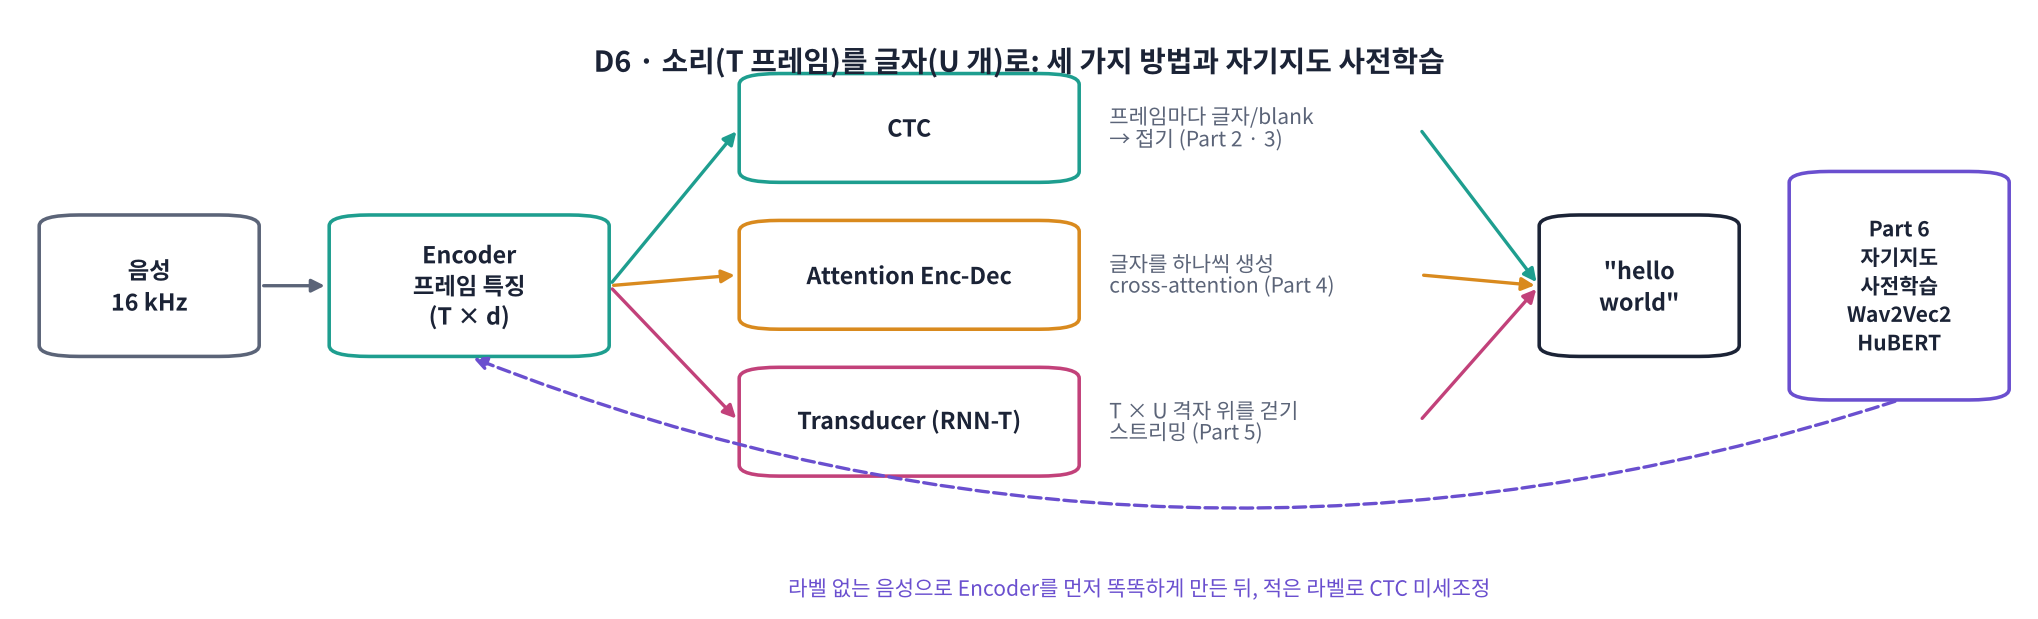

| 교시 | 내용 | 실습 |
|---|---|---|
| 1교시 | ASR 문제 정의(정렬 문제), CTC: blank · 접기 규칙 · 경로 수 · forward 알고리즘 | Part 0 ~ 2, 워크시트 1교시 |
| 2교시 | Wav2Vec2 + CTC 실전: 프레임 수 공식, greedy 디코딩, CTC 스파이크, 타임스탬프 | Part 3, 워크시트 2교시 |
| 3교시 | Attention Encoder-Decoder(Whisper 맛보기), Transducer 격자, 세 방식 비교 | Part 4 ~ 5, 워크시트 3교시 |
| 4교시 | 자기지도 학습: wav2vec 2.0 대조 학습, HuBERT 가짜 라벨, 정리 | Part 6 ~ 7, 워크시트 4교시 · 노션 제출 |

## 오늘의 수업 자료
| 자료 | 링크 | 언제 쓰나요 |
|---|---|---|
| 🎬 인터랙티브 애니메이션 | [animation.html](https://imguru-mooc.github.io/AI_Voice/day06/animation.html) | 각 Part 설명을 볼 때 (Part마다 바로가기 링크가 있습니다) |
| 📝 개념 워크시트 | [worksheet.html](https://imguru-mooc.github.io/AI_Voice/day06/worksheet.html) | 각 교시 끝에 해당 탭 10문항 (4교시 × 10문항), 오답 캡처 → 노션 |

## 이 노트북 사용법
- ▶️ 일반 코드 셀은 위에서부터 차례로 실행합니다.
- 🧩 **빈칸 실습** 셀은 `____`(밑줄 4개)를 지우고 알맞은 값을 채운 뒤 실행합니다. 마지막 줄에서 ✅ 또는 ❌로 결과를 알려줍니다.
- 🔑 **정답 및 해설 보기**를 클릭하면 정답이 펼쳐집니다.
- 📐 **수식으로 보기**에서 원리를 수식으로 정리하고, ▶️ **수식 검증** 셀에서 예측값과 측정값을 비교합니다. 🔍 **코드 해설**은 주요 코드를 한 줄씩 설명합니다.

> ⚙️ **GPU 런타임을 권장합니다** ([런타임] → [런타임 유형 변경] → **T4 GPU**). 오늘 쓰는 모델은 모두 작아서(약 4천만 ~ 1억 개 파라미터) **CPU에서도 끝까지 돌아갑니다.** 처음 실행할 때 모델 4개(Wav2Vec2 · Whisper-tiny · wav2vec2-base · HuBERT, 합계 약 1.2 GB)를 내려받습니다.

> 🎬 **애니메이션 D6-1:** [오늘의 흐름](https://imguru-mooc.github.io/AI_Voice/day06/animation.html#flow) — Part 1~6 로드맵

> ## 🎤 강사 스크립트 · 1교시 도입: 정답에 '위치'가 없다  ⏱️ 5분
>
> 🎯 **음성 인식의 핵심 문제는 '정렬을 모르는 채로 배우기'이고, 오늘 배우는 세 방법은 그 해법 세 가지다.**
>
> 🖥️ 슬라이드 p.1(표지) → p.2(오늘 답할 질문) → 노트북 표지 흐름 그림.
>
> 🗣️ "어제는 1초짜리 녹음 하나에 단어 하나, 정답도 하나였습니다. 오늘부터는 **문장**을 받아 적습니다. 그런데 문제가 생깁니다. 2초짜리 녹음은 20 ms마다 한 장씩 사진(프레임)을 찍으면 100장인데, 정답 'hello world'는 글자 11개입니다. 그리고 **'몇 번째 사진이 h인지'는 정답지에 없습니다.**"
>
> 🍎 "받아쓰기 시험 채점표를 떠올려 보세요. 정답 문장만 적혀 있고, '선생님이 몇 초에 이 글자를 말했다'는 없죠. 그래도 우리는 받아쓰기를 배웠습니다. 오늘은 컴퓨터가 그걸 어떻게 배우는지, 세 가지 방법을 봅니다."
>
> 🖥️ 애니메이션 [D6-1 오늘의 흐름](https://imguru-mooc.github.io/AI_Voice/day06/animation.html#flow)에서 Part 1 ~ 6을 눌러 보여 줍니다.
>
> ⚠️ **지금 바로** 학생들에게 Part 0 셀 3개와 Part 3의 첫 셀(모델 불러오기)을 실행하게 하세요. 모델 다운로드가 설명하는 동안 끝납니다.
>
> ➡️ "다운로드가 도는 동안, 먼저 문제를 눈으로 확인해 봅시다."

## Part 0. 준비

`transformers`, `torch`, `librosa`, `scikit-learn`은 Colab에 이미 설치되어 있습니다. 시험용 음성을 만들 **gTTS**만 설치합니다. **torch를 pip로 다시 설치하지 마세요** (버전이 어긋나면 import 오류가 납니다).

> ## 🎤 강사 스크립트 · Part 0 준비  ⏱️ 3분
>
> 🎯 **오늘 쓰는 시험 음성은 gTTS로 만든 영어 문장 하나다. 모든 Part가 이 `y_en`을 쓴다.**
>
> 🗣️ (설치 셀) "오늘 설치하는 것은 gTTS 하나입니다. transformers, torch는 Colab에 이미 있습니다."
>
> 🗣️ (음성 셀) "'speech recognition turns sound into text'를 합성했습니다. 영어인 이유는 오늘 쓰는 Wav2Vec2 모델이 영어로 학습되었기 때문입니다. 한국어 모델은 과제 1과 3주차에서 씁니다."
>
> ✅ 예상 출력: `길이: 약 40,000 ~ 48,000 샘플 = 2.5 ~ 3.0초` (gTTS 버전에 따라 조금 다름)
>
> ⚠️ gTTS 오류(`gTTSError: Failed to connect`) → 망 문제. 강사가 공유한 `en.mp3`로 대체.

In [ ]:
!pip install -q gTTS
print("✅ 설치 완료")

In [ ]:
import os, time, math, itertools, random
from itertools import groupby
import numpy as np
import librosa, librosa.display
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from IPython.display import Audio, display
from gtts import gTTS

SR = 16000
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(0); np.random.seed(0); random.seed(0)

def check(cond, hint="빈칸을 다시 확인하세요."):
    print("✅ 정답입니다! 🎉" if cond else f"❌ {hint}")

print(f"torch {torch.__version__} | device = {DEVICE}" + (f" ({torch.cuda.get_device_name(0)})" if DEVICE == "cuda" else " (CPU도 괜찮습니다)"))

In [ ]:
# 오늘의 시험 음성: gTTS로 영어 문장을 합성해 16 kHz mono로 읽기 (앞뒤 무음은 D4처럼 잘라 냄)
TEXT_EN = "speech recognition turns sound into text"

def tts(text, path, lang="en", slow=False):
    gTTS(text, lang=lang, slow=slow).save(path)
    y, _ = librosa.load(path, sr=SR, mono=True)
    y, _ = librosa.effects.trim(y, top_db=35)
    return y.astype(np.float32)

y_en = tts(TEXT_EN, "en.mp3")
print(f"문장: {TEXT_EN!r}")
print(f"길이: {len(y_en):,} 샘플 = {len(y_en) / SR:.2f}초")
display(Audio(y_en, rate=SR))

## Part 1. 음성 인식은 무엇이 어려운가: 정렬 문제

D5의 키워드 인식은 **1초 → 단어 1개**였습니다. 입력 길이도 고정, 정답도 하나였죠. 문장 받아쓰기(ASR)는 다릅니다.

### 1-1. 📐 수식으로 보기: $P(Y \mid X)$와 길이 차이

- 입력: 프레임 특징 $X = (x_1, x_2, \dots, x_T)$ — 10 ms(또는 20 ms)마다 하나
- 출력: 글자 $Y = (y_1, y_2, \dots, y_U)$
- 목표: 가장 그럴듯한 글자열 $\hat Y = \arg\max_Y P(Y \mid X)$

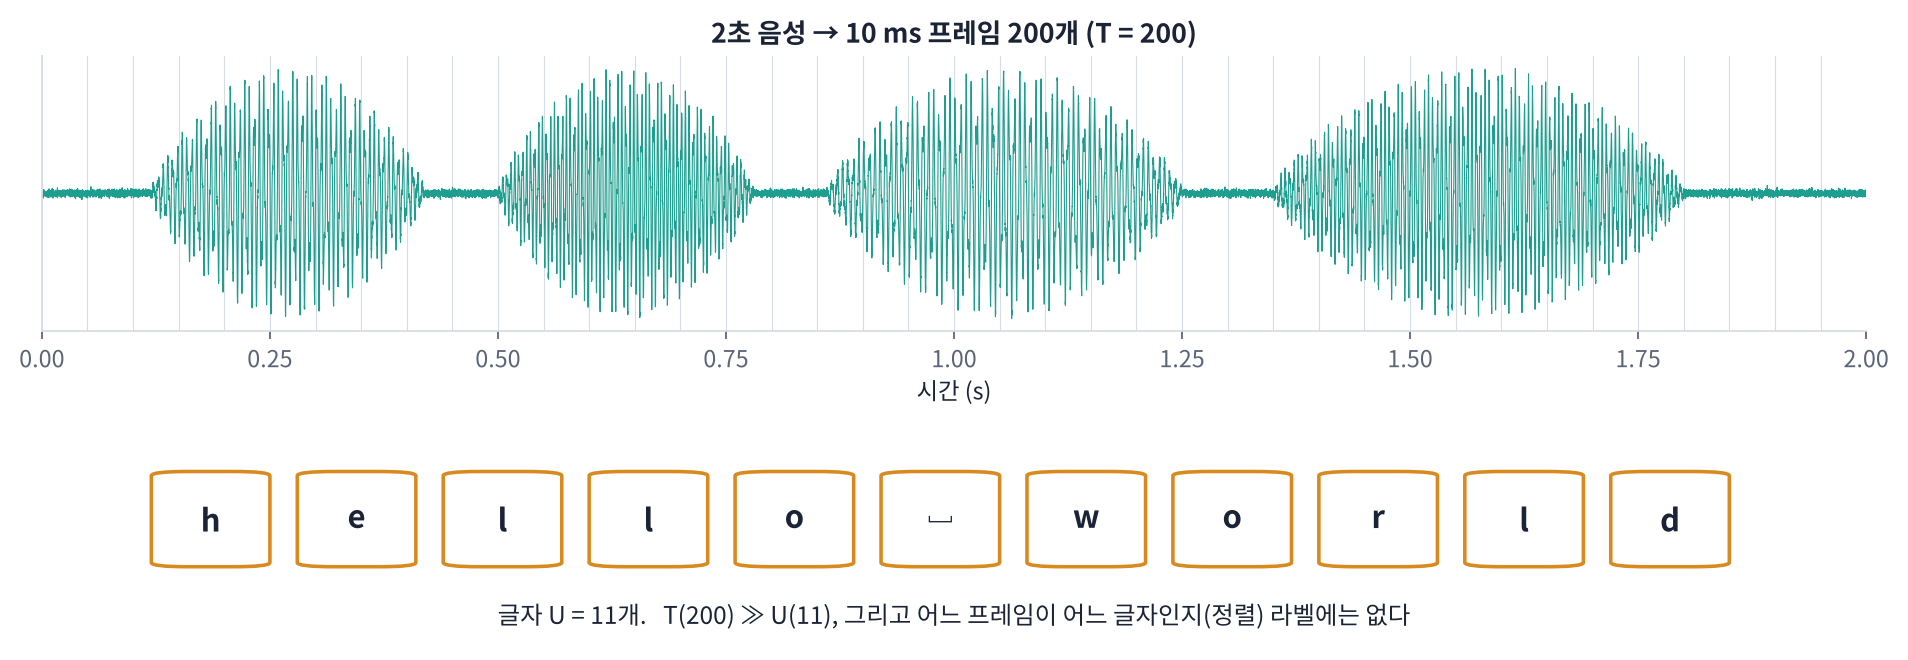

어려운 점은 두 가지입니다.
1. **길이가 다르다**: 2초 음성이면 $T = 200$(10 ms 기준), 글자는 $U \approx 11$. 보통 $T \gg U$.
2. **정렬을 모른다**: 학습 데이터에는 "이 녹음 = 'hello world'"만 있고, **몇 번째 프레임이 'h'인지는 없습니다.** 사람이 프레임마다 라벨을 다는 것은 너무 비쌉니다.

오늘 배우는 세 가지 방법은 모두 이 **"정렬을 모르는 채로 $P(Y \mid X)$를 학습하는 방법"** 입니다.

| 방법 | 정렬을 다루는 방식 | 대표 모델 |
|---|---|---|
| **CTC** | 가능한 정렬 경로를 **모두 더한다** (blank 도입) | Wav2Vec2, HuBERT 미세조정, QuartzNet |
| **Attention Encoder-Decoder (AED)** | 글자마다 **attention으로 소리 구간을 찾아본다** | Whisper, LAS |
| **Transducer (RNN-T)** | $T \times U$ 격자 위의 경로를 **모두 더한다** + 언어 모델 역할의 예측망 | Conformer-Transducer, 휴대폰 받아쓰기 |

> 🎬 **애니메이션 D6-2:** [정렬 문제](https://imguru-mooc.github.io/AI_Voice/day06/animation.html#align) — 말하는 속도를 바꿔 프레임 수와 글자 수 비교, 정렬 경로 드래그

> ## 🎤 강사 스크립트 · Part 1 정렬 문제  ⏱️ 7분
>
> 🎯 **T(프레임) ≫ U(글자), 그리고 정렬은 라벨에 없다.**
>
> 🖥️ 셀 실행 → Log-Mel 그림에서 "어디가 s이고 어디가 p인지 손가락으로 짚어 보세요" 하고 잠깐 기다립니다.
>
> ❓ "이 그림에서 'r'이 시작하는 프레임을 정확히 짚을 수 있나요?" → 예상 답: 대충은 알지만 정확히는 모름. → "모델도 마찬가지입니다. 그리고 우리는 그걸 알려 줄 수도 없어요."
>
> 🖥️ [D6-2 정렬 문제](https://imguru-mooc.github.io/AI_Voice/day06/animation.html#align): 🎲를 여러 번 눌러 같은 라벨에 다른 정렬이 계속 나오는 것을 보여 주고, 말하는 속도 슬라이더로 T가 바뀌는 것, 아래 '정렬 경로 수'가 수십만 ~ 천문학적으로 커지는 것을 보여 줍니다.
>
> 🗣️ "방법은 두 가지 철학입니다. **가능한 정렬을 전부 더한다**(CTC, Transducer), 또는 **글자마다 소리를 찾아본다**(Attention). 표의 세 줄이 오늘 하루입니다."
>
> ➡️ "첫 번째, 전부 더하기. 그런데 '정렬'을 어떻게 표현할까요? 여기서 blank가 등장합니다."

In [ ]:
# 프레임 수 T와 글자 수 U 비교 (D3의 Log-Mel, hop 10 ms)
HOP = 160
logmel = librosa.power_to_db(librosa.feature.melspectrogram(y=y_en, sr=SR, n_fft=400, hop_length=HOP, n_mels=80), ref=np.max)
T, U = logmel.shape[1], len(TEXT_EN)
print(f"Log-Mel 모양 (mel, T) = {logmel.shape}")
print(f"T = {T} 프레임, U = {U} 글자 → 글자 하나에 평균 {T / U:.1f} 프레임")

fig, ax = plt.subplots(figsize=(13, 3))
librosa.display.specshow(logmel, sr=SR, hop_length=HOP, x_axis="time", y_axis="mel", ax=ax, cmap="magma")
ax.set_title(f"'{TEXT_EN}'  (T = {T} frames, U = {U} characters) - which frame is which letter?")
plt.tight_layout(); plt.show()

## Part 2. CTC: 모든 정렬 경로를 더하기

### 2-1. 📐 수식으로 보기: blank와 접기 규칙 $\mathcal{B}$

**CTC**(Connectionist Temporal Classification, Graves 2006)는 모델이 **프레임마다** 글자 하나를 고르게 합니다. 그러면 출력이 $T$개라 너무 깁니다. 그래서 두 가지를 추가합니다.

1. **blank** $\epsilon$ (여기서는 `-`로 표시): "이 프레임에는 새 글자 없음"
2. **접기 규칙** $\mathcal{B}$: ① 연속으로 반복된 글자를 하나로 합치고 → ② blank를 지운다

$$
\mathcal{B}(\texttt{hhe-ll-lloo}) = \texttt{hello}, \qquad \mathcal{B}(\texttt{he-llll-ooo}) = \texttt{helo}
$$

길이 $T$의 프레임별 출력 $\pi = (\pi_1, \dots, \pi_T)$를 **정렬 경로**(alignment)라고 부릅니다. 모델은 프레임마다 확률 $p_t(k)$를 내고, **프레임끼리는 서로 독립**이라고 가정합니다(조건부 독립 가정).

$$
P(\pi \mid X) = \prod_{t=1}^{T} p_t(\pi_t), \qquad
P(Y \mid X) = \sum_{\pi \,\in\, \mathcal{B}^{-1}(Y)} \prod_{t=1}^{T} p_t(\pi_t)
$$

정답 $Y$로 접히는 경로를 **모두** 더하므로, 정렬을 몰라도 학습할 수 있습니다. 손실은 $\mathcal{L}_{CTC} = -\log P(Y \mid X)$.

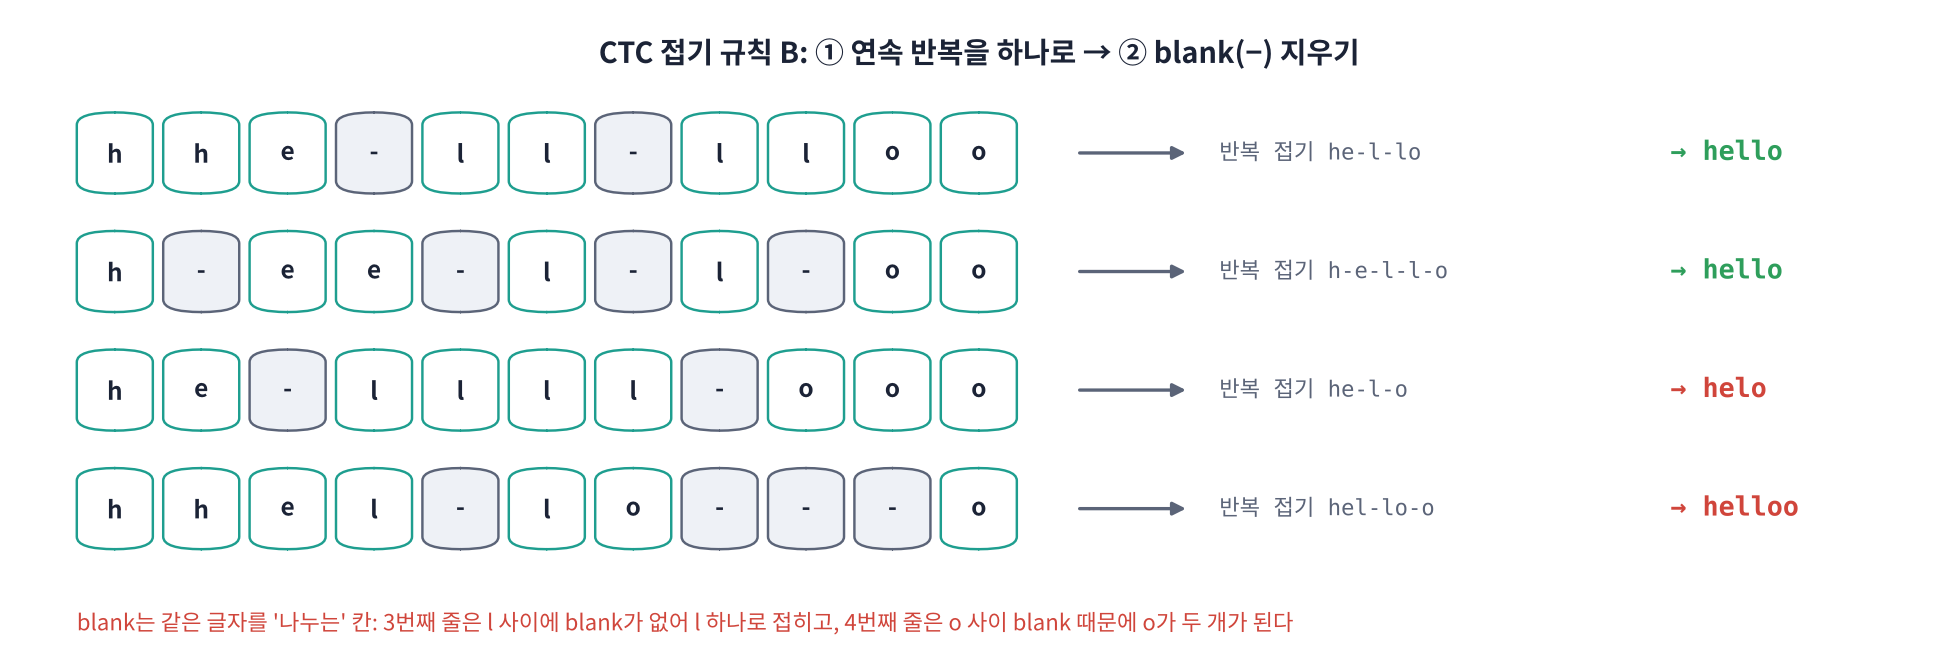

> 💡 **blank가 꼭 필요한 이유**: "hello"의 `ll`처럼 같은 글자가 연달아 나오면 ①에서 하나로 합쳐집니다. 사이에 blank를 끼워 `l-l`로 써야 두 글자로 남습니다. 그래서 $T \ge U + (\text{연속 중복 글자 수})$여야 합니다.

> 🎬 **애니메이션 D6-3:** [CTC 접기](https://imguru-mooc.github.io/AI_Voice/day06/animation.html#ctc) — 경로를 직접 입력하거나 칸을 눌러 바꾸며 접기 결과 확인

> ## 🎤 강사 스크립트 · Part 2-1 CTC blank와 접기  ⏱️ 8분
>
> 🎯 **CTC = 프레임마다 글자나 blank를 내고, '반복 합치기 → blank 지우기'로 접는다.**
>
> 🖥️ 슬라이드 p.5 → 노트북 그림. 칠판에 `hhe-ll-lloo`를 쓰고 두 단계를 손으로 해 봅니다.
>
> 🗣️ "사진마다 글자 하나씩 적게 합니다. 한 글자를 0.1초 동안 말하면 사진 5장에 같은 글자가 적히겠죠. 그래서 **연달아 같은 글자는 하나로** 합칩니다. 말 사이 쉬는 구간이나 애매한 사진에는 **'없음'(blank)** 을 적고 나중에 지웁니다."
>
> ❓ "그럼 'hello'의 ll은 어떻게 쓰죠? `llll`은 l 하나로 합쳐지는데?" → 예상 답: 사이에 blank를 넣는다(`l-l`). → 🍎 "같은 글자를 두 번 쓰려면 사이에 쉼표가 있어야 합니다."
>
> 🖥️ [D6-3 CTC 접기](https://imguru-mooc.github.io/AI_Voice/day06/animation.html#ctc): 예시 `he-llll-ooo` → 접기 ▶ → 'helo' ❌. 칸 하나를 눌러 l 사이를 −로 바꾸고 다시 접기 → 'hello' ✅. 학생 한 명에게 직접 고치게 하면 좋습니다.
>
> 🗣️ (수식) "P(Y|X)는 **정답으로 접히는 모든 경로**의 확률을 더한 것이고, 경로 확률은 프레임별 확률의 곱입니다. 곱으로 쪼갤 수 있는 건 '프레임끼리 독립'이라고 가정했기 때문이에요. 이 가정이 CTC를 빠르게 만들지만, 앞 글자를 못 보게 만드는 약점이기도 합니다."
>
> ⚠️ 오개념: "blank = 무음". 아닙니다. 말하는 중간에도 대부분 프레임이 blank입니다(Part 3 스파이크에서 확인).

### 🧩 빈칸 실습 1: 접기 함수 `ctc_collapse()`
`groupby`로 연속 반복을 하나로 합친 뒤, **blank가 아닌 것만** 남기세요.

In [ ]:
# 🧩 빈칸 실습 1
BLANK = "-"

def ctc_collapse(path, blank=BLANK):
    merged = [k for k, _ in groupby(path)]          # ① 연속 반복 → 하나
    return [k for k in merged if k != ____]         # ② blank 지우기

tests = {"hhe-ll-lloo": "hello", "he-llll-ooo": "helo", "--c-aa--tt-": "cat", "hhel-lo---o": "helloo", "-----": ""}
for p, want in tests.items():
    got = "".join(ctc_collapse(p))
    print(f"{p:>12s} → {got!r:9s} {'✅' if got == want else '❌'}")
check(all("".join(ctc_collapse(p)) == w for p, w in tests.items()), hint="두 번째 줄에서 지울 것은 blank입니다.")

> ## 🎤 강사 스크립트 · 🧩 빈칸 1 힌트  ⏱️ 3분
>
> 🆘 1단계: "두 번째 줄은 무엇을 **지우는** 줄인가요?" → blank
> 🆘 2단계: "함수 인자 이름을 보세요. `blank=BLANK`라고 받았죠."
> 🆘 3단계: 정답 `k != blank`
>
> ✅ 예상 출력: 다섯 줄 모두 ✅, 마지막에 `✅ 정답입니다! 🎉`
>
> ❓ (빨리 끝난 학생) "순서를 바꿔서 blank를 먼저 지우면 'hhe-ll-lloo'는 무엇이 될까요?" → `hello`가 아니라 `helo`.

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
return [k for k in merged if k != blank]
```

**해설**: `groupby`는 연속으로 같은 값을 한 묶음으로 돌려주므로 `[k for k, _ in groupby(path)]`가 ①, blank 거르기가 ②입니다. **순서가 중요합니다.** blank를 먼저 지우면 `l-l`이 `ll` → `l`로 합쳐져 버립니다. `BLANK` 상수를 써도 되지만 인자 `blank`를 써야 Part 3에서 Wav2Vec2의 blank(`<pad>`)에도 그대로 쓸 수 있습니다.

</details>

### 2-2. 📐 경로는 몇 개나 될까: 다 더하는 건 불가능

어휘 $V$개(+ blank)에서 길이 $T$ 경로는 $(V+1)^T$개입니다. 그중 정답 $Y$로 접히는 경로 수는, $Y$에 연속 중복 글자가 없을 때

$$
\left| \mathcal{B}^{-1}(Y) \right| = \binom{T + U}{2U}
$$

작은 예로 직접 세어 보고, 실제 크기를 계산해 봅니다.

In [ ]:
def all_alignments(target, T, vocab):
    # (V+1)^T 개를 전부 만들어 보고 target으로 접히는 것만 남기기 (작은 T에서만!)
    return ["".join(p) for p in itertools.product(vocab, repeat=T) if "".join(ctc_collapse(p)) == target]

paths = all_alignments("cat", 5, ["-", "c", "a", "t"])
print(f"T=5, 'cat' 으로 접히는 경로: {len(paths)}개 (공식 C(8, 6) = {math.comb(8, 6)})")
print("  예:", paths[:8], "...")

T_real, U_real = 150, 40     # 3초 음성(20 ms 프레임), 40글자
print(f"\n실제 크기: T={T_real}, U={U_real} → 경로 약 10^{math.log10(math.comb(T_real + U_real, 2 * U_real)):.0f}개 → 하나씩 더하는 것은 불가능")

### 2-3. 📐 수식으로 보기: forward(α) 알고리즘

경로를 하나씩 더하는 대신 **동적 계획법**으로 겹치는 계산을 재사용합니다.

**확장 라벨**: 정답 글자 사이사이와 양 끝에 blank를 넣습니다. $Y = \texttt{cat} \Rightarrow l' = (\epsilon, c, \epsilon, a, \epsilon, t, \epsilon)$, 길이 $S = 2U + 1$.

$\alpha_t(s)$ = "프레임 $t$까지 보고 $l'$의 $s$번째 칸에 와 있는 모든 경로의 확률 합"

$$
\alpha_t(s) = \Big( \alpha_{t-1}(s) + \alpha_{t-1}(s-1) + \underbrace{\alpha_{t-1}(s-2)}_{l'_s \ne \epsilon \;\text{그리고}\; l'_s \ne l'_{s-2} \text{일 때만}} \Big) \cdot p_t(l'_s)
$$

- 시작: $\alpha_1(0) = p_1(\epsilon)$, $\alpha_1(1) = p_1(y_1)$ (blank로 시작하거나 첫 글자로 시작)
- 끝: $P(Y \mid X) = \alpha_T(S-1) + \alpha_T(S-2)$ (마지막 blank 또는 마지막 글자에서 끝)
- 계산량: $O(T \cdot S)$ — 경로 수 $\binom{T+U}{2U}$와 비교하면 엄청나게 적음

**두 칸 건너뛰기($s-2 \to s$)** 는 사이의 blank를 건너뛰는 것입니다. 단, $l'_s$가 blank이거나 **두 칸 앞과 같은 글자**면 금지입니다. 같은 글자 사이의 blank를 건너뛰면 접을 때 하나로 합쳐지기 때문입니다.

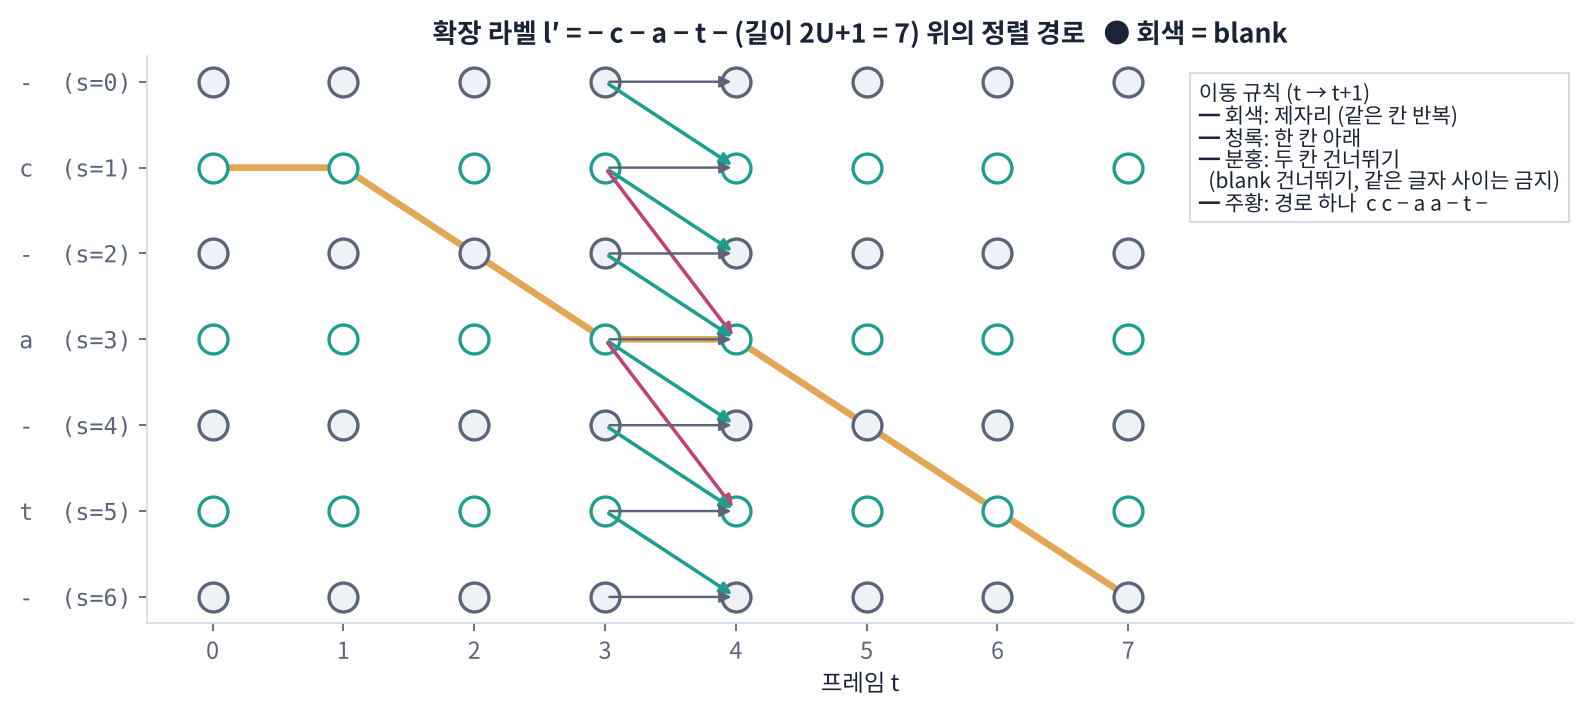

> 🎬 **애니메이션 D6-4:** [CTC 격자와 α](https://imguru-mooc.github.io/AI_Voice/day06/animation.html#ctcloss) — 프레임을 한 칸씩 진행하며 α 값이 채워지는 과정, 경로 수 세기

> ## 🎤 강사 스크립트 · Part 2-2 ~ 2-3 경로 수와 α  ⏱️ 12분
>
> 🎯 **경로는 너무 많아서 다 셀 수 없다 → 격자 위에서 '여기까지 오는 합'을 적어 가며 이어 간다(α).**
>
> 🖥️ 경로 세기 셀 실행: `cat`, T=5에서 28개, 공식 C(8, 6) = 28이 같은 것을 확인. 실제 크기 10^55를 읽어 줍니다.
>
> 🗣️ "우주의 원자 수가 10^80쯤입니다. 3초짜리 문장 하나의 경로 수가 10^55. 하나씩 더하는 건 불가능합니다."
>
> 🍎 "계단 오르기 문제 아세요? '한 칸 또는 두 칸씩 오를 때 10층까지 가는 방법 수'를 구할 때, 1층, 2층… 각 층까지 오는 방법 수를 적어 가면서 올라가죠. α가 정확히 그겁니다. 각 칸에 '여기까지 오는 모든 경로의 확률 합'을 적어 둡니다."
>
> 🖥️ [D6-4 CTC 격자 · α](https://imguru-mooc.github.io/AI_Voice/day06/animation.html#ctcloss):
> 1. 먼저 '경로 수 세기'를 켜고 cat, T=5 → "끝까지" → 끝 숫자가 28. "방금 노트북 숫자와 같죠?"
> 2. 끄고 '한 프레임 ▶'을 천천히: 화살표 세 종류(제자리 · 한 칸 · 건너뛰기)를 짚어 줍니다.
> 3. **baa**로 바꿔 a(s=3) → a(s=5) 건너뛰기 화살표가 **없는** 것을 보여 줍니다. 이것이 빈칸 2입니다.
>
> ❓ "왜 blank를 건너뛰면 안 될까요? (s=2 → s=4)" → 예상 답: blank 칸으로 '건너뛰어' 들어가는 건 의미가 없음, blank는 거쳐 가거나 머무는 칸. 정확히는 l′_s가 blank면 두 칸 전도 blank가 아니라 글자인데, 글자→다음 blank는 한 칸 이동으로 충분합니다.
>
> ⚠️ 수식이 어려워하는 학생에게: "규칙은 세 개입니다. 옆으로 그대로, 한 칸 아래로, 그리고 조건부로 두 칸 아래로. 조건만 기억하세요: **다음 칸이 글자이고, 두 칸 위와 다른 글자일 때.**"

### 🧩 빈칸 실습 2: 두 칸 건너뛰기 조건
$s-2$에서 $s$로 건너뛰려면 $l'_s$가 blank가 아니고, **$l'_{s-2}$와도 달라야** 합니다.

In [ ]:
# 🧩 빈칸 실습 2
def ctc_forward(probs, target, vocab, blank=BLANK):
    # probs: (T, V) 프레임마다 확률 (각 행의 합 = 1), target: 정답 문자열
    idx = {c: i for i, c in enumerate(vocab)}
    lp = [blank]
    for ch in target:
        lp += [ch, blank]                                   # 확장 라벨 l' (길이 2U+1)
    S, T = len(lp), len(probs)
    alpha = np.zeros((T, S))
    alpha[0, 0] = probs[0, idx[lp[0]]]                      # blank로 시작
    alpha[0, 1] = probs[0, idx[lp[1]]]                      # 첫 글자로 시작
    for t in range(1, T):
        for s in range(S):
            a = alpha[t - 1, s]                             # 제자리
            if s >= 1:
                a += alpha[t - 1, s - 1]                    # 한 칸 아래
            if s >= 2 and lp[s] != blank and lp[s] != ____:
                a += alpha[t - 1, s - 2]                    # 두 칸 건너뛰기
            alpha[t, s] = a * probs[t, idx[lp[s]]]
    return alpha, alpha[-1, -1] + alpha[-1, -2]

rng = np.random.default_rng(0)
vocab = ["-", "a", "b", "c", "t"]
probs = rng.dirichlet(np.ones(len(vocab)), size=6)          # T=6 프레임의 임의 확률

def brute(probs, target, vocab):                            # 정답: 경로를 전부 더하기
    return sum(np.prod([probs[t, vocab.index(ch)] for t, ch in enumerate(p)])
               for p in all_alignments(target, len(probs), vocab))

for tgt in ["cat", "baa"]:
    _, p_alpha = ctc_forward(probs, tgt, vocab)
    print(f"{tgt}: α 알고리즘 {p_alpha:.6e} | 전부 더하기 {brute(probs, tgt, vocab):.6e}")
check(all(np.isclose(ctc_forward(probs, t, vocab)[1], brute(probs, t, vocab)) for t in ["cat", "baa", "ab"]),
      hint="'baa'처럼 같은 글자가 연달아 나오는 경우가 틀립니다. 두 칸 앞의 라벨 lp[s - 2]와 비교하세요.")

> ## 🎤 강사 스크립트 · 🧩 빈칸 2 힌트 · 수식 검증 1  ⏱️ 7분
>
> 🆘 1단계: "'cat'은 ✅인데 'baa'만 틀리나요? 그러면 같은 글자 연속이 문제입니다."
> 🆘 2단계: "건너뛰기는 s−2에서 s로 오는 것. 두 칸이 **같은 글자면** 금지입니다. 비교할 대상은?"
> 🆘 3단계: 정답 `lp[s] != lp[s - 2]`
>
> ✅ 예상 출력: `cat: α 알고리즘 … | 전부 더하기 …` 두 값이 같고, `✅ 정답입니다! 🎉`
>
> 🖥️ 수식 검증 1 셀: "세 가지 방법(전부 더하기 84개 경로, 우리 α, PyTorch F.ctc_loss)의 −log P가 소수점 다섯째 자리까지 같습니다. **PyTorch 내부도 똑같은 α를 돌린다**는 증거입니다."
>
> 🗣️ (코드 해설 표) "실전에서 제일 많이 틀리는 건 `log_probs` 모양입니다. **(T, N, C), 시간이 첫 번째**입니다. 모델 출력은 보통 (N, T, C)라서 `transpose(0, 1)`이 필요합니다."
>
> ⚠️ α 그림(정규화 히트맵)에서 "대각선 띠" 모양이 나오는 이유: 정답 순서대로만 내려갈 수 있기 때문(단조 정렬).

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
if s >= 2 and lp[s] != blank and lp[s] != lp[s - 2]:
```

**해설**: 'cat'은 연속 중복이 없어서 조건을 빼먹어도 맞게 나오지만, **'baa'에서 차이가 납니다.** $l' = (\epsilon, b, \epsilon, a, \epsilon, a, \epsilon)$에서 첫 `a`(s=3) → 둘째 `a`(s=5)로 건너뛰면 경로가 `…aa…`가 되어 접을 때 `a` 하나로 합쳐집니다. 그런 경로는 'ba'로 접히므로 'baa'의 합에 들어가면 안 됩니다.

</details>

In [ ]:
# ▶️ 수식 검증 1: 내 α 알고리즘 = 전부 더하기 = PyTorch F.ctc_loss
T6 = len(probs)
log_probs = torch.log(torch.tensor(probs, dtype=torch.float32)).unsqueeze(1)      # (T, N=1, V)
for tgt in ["cat", "baa"]:
    targets = torch.tensor([[vocab.index(c) for c in tgt]])
    loss = F.ctc_loss(log_probs, targets, input_lengths=torch.tensor([T6]), target_lengths=torch.tensor([len(tgt)]),
                      blank=0, reduction="sum")
    alpha, p_alpha = ctc_forward(probs, tgt, vocab)
    print(f"{tgt}: −log P  α = {-np.log(p_alpha):.5f} | F.ctc_loss = {loss.item():.5f} | 경로 {len(all_alignments(tgt, T6, vocab))}개")

# α 표를 그림으로: 행 = 확장 라벨 칸 s, 열 = 프레임 t
alpha, _ = ctc_forward(probs, "cat", vocab)
fig, ax = plt.subplots(figsize=(7, 3.6))
im = ax.imshow(alpha.T / alpha.sum(1), cmap="viridis", aspect="auto")
ax.set_yticks(range(7)); ax.set_yticklabels(list("-c-a-t-")); ax.set_xlabel("frame t"); ax.set_ylabel("extended label s")
ax.set_title("alpha_t(s) (normalized per frame)"); plt.colorbar(im); plt.tight_layout(); plt.show()

#### 🔍 코드 해설: `F.ctc_loss`

| 인자 | 모양 · 뜻 |
|---|---|
| `log_probs` | $(T, N, C)$ — **시간이 첫 번째 축**, **log_softmax를 거친 값**. 모델 출력이 $(N, T, C)$면 `.transpose(0, 1)` |
| `targets` | $(N, S_{max})$ 정답 글자 번호 (blank 번호는 들어가면 안 됨) |
| `input_lengths` | 샘플마다 실제 프레임 수 $T$ (패딩 제외) |
| `target_lengths` | 샘플마다 정답 글자 수 $U$ |
| `blank=0` | blank의 번호. Wav2Vec2는 `<pad>`가 0번이라 그대로 0 |
| `reduction` | `"mean"`(기본, 글자 수로 나눈 뒤 평균), `"sum"`, `"none"` |
| `zero_infinity=True` | $T$가 너무 짧아 가능한 경로가 없을 때 손실이 ∞가 되는 것을 0으로 처리 (실전 학습에서 자주 켬) |

> 💡 내부에서는 확률을 곱하면 0으로 사라지는(underflow) 문제를 피하려고 α를 **log 공간**에서 `logsumexp`로 계산합니다. 우리 구현은 짧은 예라서 확률 그대로 곱했습니다.

---
### 📝 1교시 마무리: 개념 워크시트

> **[worksheet.html 열기 → 1교시 탭](https://imguru-mooc.github.io/AI_Voice/day06/worksheet.html)** — 정렬 문제, $T \gg U$, CTC blank, 접기 규칙 $\mathcal{B}$, 조건부 독립 가정, 경로 수 $\binom{T+U}{2U}$, 확장 라벨 $2U+1$, α 점화식과 두 칸 건너뛰기, `F.ctc_loss`
>
> 10문항을 풀고 **채점하기**를 누르세요. 결과 코드와 해설이 나옵니다. 채점 후에는 답이 잠깁니다. 제출은 4교시까지 모두 마친 뒤 한 번에 합니다.

> ## 🎤 강사 스크립트 · 1교시 마무리 → 2교시 도입  ⏱️ 5분 + 휴식
>
> 🖥️ [worksheet.html 1교시 탭](https://imguru-mooc.github.io/AI_Voice/day06/worksheet.html) 10문항. 채점 후 결과 코드 확인.
>
> 자주 틀리는 문항: **3번 `aa-b-bb--c`** (답 abbc — b 사이 blank 때문에 b 두 개), **9번 baa 건너뛰기** (X). 틀린 학생이 많으면 D6-3에 그 경로를 입력해 보여 주세요.
>
> ➡️ (휴식 후) "지금까지는 우리가 만든 가짜 확률표로 놀았습니다. 이제 진짜 모델이 내는 확률표로 같은 일을 해 봅시다."

## Part 3. Wav2Vec2 + CTC로 실제 음성 받아 적기

`facebook/wav2vec2-base-960h`는 **라벨 없는 LibriSpeech 960시간으로 자기지도 사전학습**(Part 6)한 뒤, 같은 960시간의 받아쓰기 라벨로 **CTC 미세조정**한 영어 모델입니다.

### 3-1. 📐 수식으로 보기: 파형 → 프레임 수

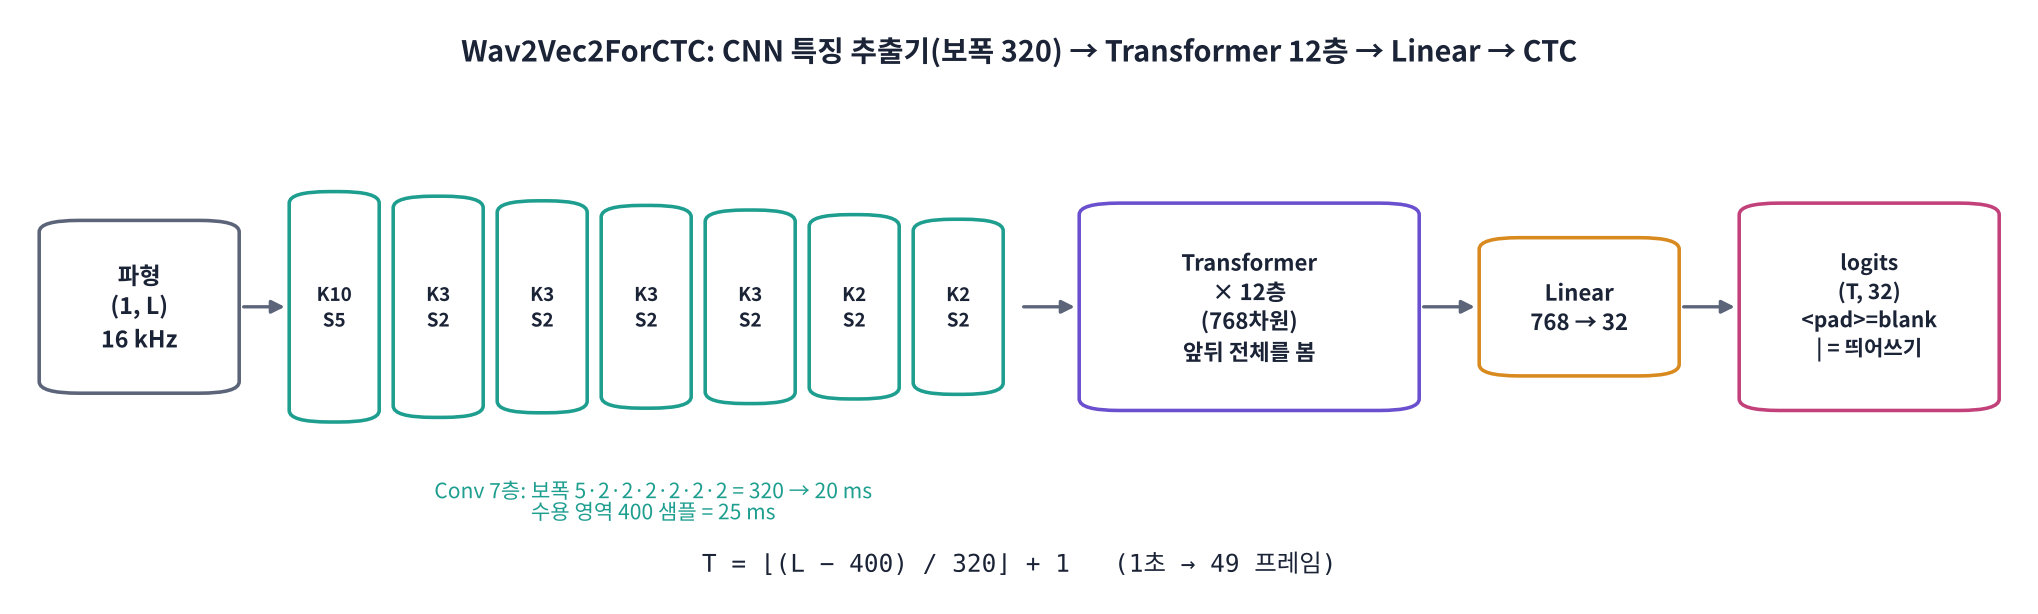

D3에서는 STFT로 프레임을 만들었지만, Wav2Vec2는 **파형을 직접 1D 합성곱 7층**에 넣어 프레임을 만듭니다. D5의 출력 크기 공식(패딩 0)을 층마다 적용하면 됩니다.

$$
L_{i} = \left\lfloor \frac{L_{i-1} - K_i}{S_i} \right\rfloor + 1, \qquad K = (10, 3, 3, 3, 3, 2, 2), \quad S = (5, 2, 2, 2, 2, 2, 2)
$$

7층을 한 번에 쓰면 **전체 보폭**(stride)과 **수용 영역**(receptive field, 출력 한 칸이 보는 입력 범위)이 나옵니다.

$$
S_{tot} = \prod_i S_i = 320 \;(= 20\text{ ms}), \qquad
R = 1 + \sum_i (K_i - 1) \prod_{j < i} S_j = 400 \;(= 25\text{ ms}), \qquad
T = \left\lfloor \frac{L - R}{S_{tot}} \right\rfloor + 1
$$

D3에서 고른 창 25 ms · hop 10 ms와 비교하면 창은 같고, 간격은 2배(20 ms)입니다. 1초 = 49 프레임.

> 🎬 **애니메이션 D6-5:** [Wav2Vec2 프레임과 CTC 출력](https://imguru-mooc.github.io/AI_Voice/day06/animation.html#w2v) — 층마다 길이가 줄어드는 과정, 프레임별 글자 확률 보기

> ## 🎤 강사 스크립트 · Part 3-1 Wav2Vec2와 프레임 수  ⏱️ 8분
>
> 🎯 **Wav2Vec2는 파형을 직접 CNN 7층으로 썰어 20 ms 프레임을 만든다. 1초 = 49 프레임.**
>
> 🖥️ 슬라이드 p.8 → 모델 불러오기 셀. 어휘 출력에서 `<pad>`가 0번, `|`가 띄어쓰기인 것을 짚습니다.
>
> 🗣️ "D3에서는 STFT로 25 ms 창, 10 ms 간격으로 사진을 찍었죠. Wav2Vec2는 STFT를 쓰지 않고 **파형을 바로 합성곱**에 넣습니다. 커널 10, 보폭 5짜리 층 하나, 그다음 보폭 2짜리 층 여섯 개. 보폭을 곱하면 5 × 2⁶ = 320샘플 = 20 ms입니다."
>
> 🍎 "긴 소시지를 칼로 일곱 번 썰어 요약하는 것과 같습니다. 칼질할 때마다 길이가 대략 5분의 1, 2분의 1, 2분의 1…로 줄어요."
>
> 🖥️ [D6-5 Wav2Vec2](https://imguru-mooc.github.io/AI_Voice/day06/animation.html#w2v) 위쪽: 길이 슬라이더를 16,000(1초)에 두고 층마다 16000 → 3199 → 1599 → … → 49를 읽어 줍니다. 400 미만으로 내리면 프레임이 0개가 되는 것도 보여 주세요.
>
> ❓ "1초에 49프레임이면 20 ms × 49 = 0.98초. 왜 50이 아닐까요?" → 첫 프레임이 400샘플(25 ms)을 다 봐야 나오기 때문.

In [ ]:
from transformers import Wav2Vec2ForCTC, Wav2Vec2Processor

W2V = "facebook/wav2vec2-base-960h"
processor = Wav2Vec2Processor.from_pretrained(W2V)
w2v = Wav2Vec2ForCTC.from_pretrained(W2V).to(DEVICE).eval()

tok = processor.tokenizer
vocab_w2v = tok.get_vocab()
id2tok = {i: t for t, i in vocab_w2v.items()}
print(f"어휘 {len(vocab_w2v)}개:", " ".join(id2tok[i] for i in range(len(id2tok))))
print(f"blank = {tok.pad_token!r} (번호 {tok.pad_token_id}), 띄어쓰기 = {tok.word_delimiter_token!r}")
print(f"conv_kernel = {w2v.config.conv_kernel}, conv_stride = {w2v.config.conv_stride}")
print(f"파라미터 {sum(p.numel() for p in w2v.parameters()) / 1e6:.1f}M")

### 🧩 빈칸 실습 3: 프레임 수 공식
수용 영역 $R$과 전체 보폭 $S_{tot}$를 계산했습니다. 한 줄 공식 $T = \lfloor (L - R) / S_{tot} \rfloor + 1$을 완성하고, 층마다 계산한 값 · 실제 모델 출력과 같은지 확인하세요.

In [ ]:
# 🧩 빈칸 실습 3
def n_frames_layerwise(L, kernels=w2v.config.conv_kernel, strides=w2v.config.conv_stride):
    for k, s in zip(kernels, strides):
        L = (L - k) // s + 1                 # D5의 출력 크기 공식 (P=0)
    return L

R, jump = 1, 1
for k, s in zip(w2v.config.conv_kernel, w2v.config.conv_stride):
    R += (k - 1) * jump                      # 수용 영역이 넓어지는 양
    jump *= s                                # 지금까지의 보폭 곱
S_TOT = jump
print(f"수용 영역 R = {R} 샘플 ({R / SR * 1000:.0f} ms), 전체 보폭 = {S_TOT} 샘플 ({S_TOT / SR * 1000:.0f} ms)")

L = len(y_en)
T_formula = (L - R) // ____ + 1

inputs = processor(y_en, sampling_rate=SR, return_tensors="pt")
with torch.no_grad():
    logits = w2v(inputs.input_values.to(DEVICE)).logits.cpu()          # (1, T, 32)
print(f"L = {L:,} 샘플 → 공식 {T_formula} | 층별 {n_frames_layerwise(L)} | 모델 출력 {tuple(logits.shape)}")
check(T_formula == n_frames_layerwise(L) == logits.shape[1], hint="나누는 값은 전체 보폭 S_TOT(320)입니다.")

> ## 🎤 강사 스크립트 · 🧩 빈칸 3 힌트  ⏱️ 4분
>
> 🆘 1단계: "STFT 프레임 수 공식 ⌊(L − 창)/hop⌋ + 1을 기억하나요? 여기서 '창'은 R, 'hop'은?"
> 🆘 2단계: "바로 위에서 계산한 변수 중 '보폭을 다 곱한 것'은?"
> 🆘 3단계: 정답 `S_TOT`
>
> ✅ 예상 출력: `수용 영역 R = 400 샘플 (25 ms), 전체 보폭 = 320 샘플 (20 ms)`, `공식 N | 층별 N | 모델 출력 (1, N, 32)` 세 값이 같음 (N은 약 130~150), `✅`
>
> 🗣️ "모델을 돌려 보지 않고도 출력 길이를 미리 알 수 있습니다. 배포할 때 메모리와 지연을 계산하는 기본입니다."

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
T_formula = (L - R) // S_TOT + 1
```

**해설**: 보폭이 5, 2, 2, …로 곱해져 한 출력 칸이 입력에서 $320$샘플씩 이동하고, 첫 칸은 입력 $R = 400$샘플을 봅니다. 그래서 '창 400, hop 320'인 STFT와 같은 개수가 나옵니다. 층별 바닥 함수를 한 번에 써도 결과가 같은 이유는 $\lfloor \lfloor x \rfloor / n \rfloor = \lfloor x / n \rfloor$ (정수 $n$) 때문입니다. 1초면 $\lfloor 15600/320 \rfloor + 1 = 49$입니다.

</details>

### 3-2. greedy 디코딩: 프레임마다 가장 큰 칸 → 접기

CTC 모델의 가장 간단한 디코딩은 **프레임마다 확률이 가장 큰 칸**을 고른 뒤 Part 2의 접기 규칙을 적용하는 것입니다.

$$
\pi_t^* = \arg\max_k \, p_t(k), \qquad \hat Y = \mathcal{B}(\pi^*)
$$

엄밀히는 "가장 확률이 큰 **경로**"이지 "가장 확률이 큰 **글자열**"은 아닙니다(같은 글자열로 접히는 다른 경로들의 합을 무시). 그래도 실전에서 거의 차이가 없어 가장 많이 씁니다. 더 정확한 **빔 서치**와 언어 모델 결합은 D7 · D8에서 다룹니다.

### 🧩 빈칸 실습 4: greedy 디코딩
`logits` 모양은 `(1, T, 32)`입니다. **어휘 방향**(마지막 축)에서 가장 큰 번호를 고르세요. 그다음은 빈칸 1의 `ctc_collapse()`를 그대로 씁니다.

In [ ]:
# 🧩 빈칸 실습 4
ids = logits.argmax(dim=____)[0]                                  # (T,) 프레임마다 가장 큰 칸 번호
path = [id2tok[i] for i in ids.tolist()]
text_mine = "".join(ctc_collapse(path, blank=tok.pad_token)).replace(tok.word_delimiter_token, " ")
text_mine = " ".join(text_mine.split())
text_hf = processor.batch_decode(ids.unsqueeze(0))[0]

show = "".join("-" if p == tok.pad_token else p for p in path)
print("프레임별 경로 (- = blank):")
for i in range(0, len(show), 70):
    print("   ", show[i:i + 70])
print(f"\n내 디코딩    : {text_mine}")
print(f"processor   : {text_hf}")
print(f"정답 (소문자): {TEXT_EN}")
check(len(ids) == logits.shape[1] and text_mine == " ".join(text_hf.split()), hint="어휘 방향은 마지막 축 dim=-1 (또는 2)입니다.")

> ## 🎤 강사 스크립트 · Part 3-2 greedy 디코딩 · 🧩 빈칸 4 · 스파이크  ⏱️ 12분
>
> 🎯 **프레임마다 1등 → 빈칸 1의 접기 함수 = 받아쓰기 완성. 대부분 프레임은 blank(스파이크).**
>
> 🆘 빈칸 4: 1단계 "logits 모양을 읽어 보세요: (1, T, 32). 32는 무엇의 개수?" → 어휘. 2단계 "어휘 방향은 몇 번째 축?" → 마지막(-1 또는 2). 정답 `dim=-1`.
>
> ⚠️ `dim=1`로 하면 길이 32짜리 이상한 결과가 나옵니다. D5에서는 (B, 10)이라 dim=1이 맞았던 것과 헷갈리는 학생이 많습니다. **모양을 소리 내어 읽게** 하세요.
>
> ✅ 예상 출력: 프레임별 경로가 `----S-P-EE--CH---|...`처럼 대부분 `-`, `내 디코딩: SPEECH RECOGNITION TURNS SOUND INTO TEXT` (한두 글자 다를 수 있음), processor와 같음, `✅`
>
> 🗣️ "우리가 1교시에 만든 그 함수 하나로 진짜 음성 인식이 됐습니다. processor.batch_decode도 안에서 똑같은 일을 합니다."
>
> 🖥️ 스파이크 셀: "회색 선이 blank 확률입니다. 거의 1에 붙어 있다가 글자 순간에만 뚝 떨어지죠. 보통 **60~80%가 blank**입니다."
>
> 🍎 "수업 시간에 대부분 조용히 있다가 확실할 때만 손 드는 학생입니다."
>
> 🖥️ [D6-5 아래쪽](https://imguru-mooc.github.io/AI_Voice/day06/animation.html#w2v) '재생': 프레임이 진행되며 1등 글자가 쌓이고 접히는 과정. LL 연속 프레임이 L 하나가 되고, blank 다음 L이 따로 나오는 것을 짚어 줍니다.

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
ids = logits.argmax(dim=-1)[0]
```

**해설**: 모양이 (배치, 시간, 어휘)이므로 어휘 방향은 `dim=-1`(=2)입니다. `dim=1`로 하면 '어휘마다 가장 큰 프레임'이 나와 길이가 32가 됩니다. `processor.batch_decode`도 내부에서 똑같이 **반복 합치기 → `<pad>` 지우기 → `|`를 띄어쓰기로**를 합니다. 이 모델은 대문자로만 학습해서 출력이 대문자입니다.

</details>

In [ ]:
# CTC 스파이크: 프레임마다 blank 확률과 '글자' 확률
probs_w = logits.softmax(-1)[0]                                    # (T, 32)
pb = probs_w[:, tok.pad_token_id].numpy()
best_nb = probs_w.clone(); best_nb[:, tok.pad_token_id] = 0
pk, kk = best_nb.max(-1)
blank_ratio = (ids == tok.pad_token_id).float().mean().item()

t_sec = np.arange(len(pb)) * S_TOT / SR
fig, ax = plt.subplots(figsize=(13, 3.2))
ax.plot(t_sec, pb, color="gray", lw=1.2, label="P(blank)")
ax.bar(t_sec, pk.numpy(), width=0.015, color="tab:cyan", label="max P(letter)")
for t in range(len(pb)):
    if ids[t] != tok.pad_token_id and (t == 0 or ids[t] != ids[t - 1]):
        ax.text(t_sec[t], pk[t] + 0.03, id2tok[int(kk[t])], ha="center", fontsize=9, fontweight="bold")
ax.set_ylim(0, 1.15); ax.set_xlabel("time (s)"); ax.legend(loc="lower right")
ax.set_title(f"CTC spikes: {blank_ratio:.0%} of frames are blank")
plt.tight_layout(); plt.show()

### 3-3. CTC는 왜 '뾰족'할까

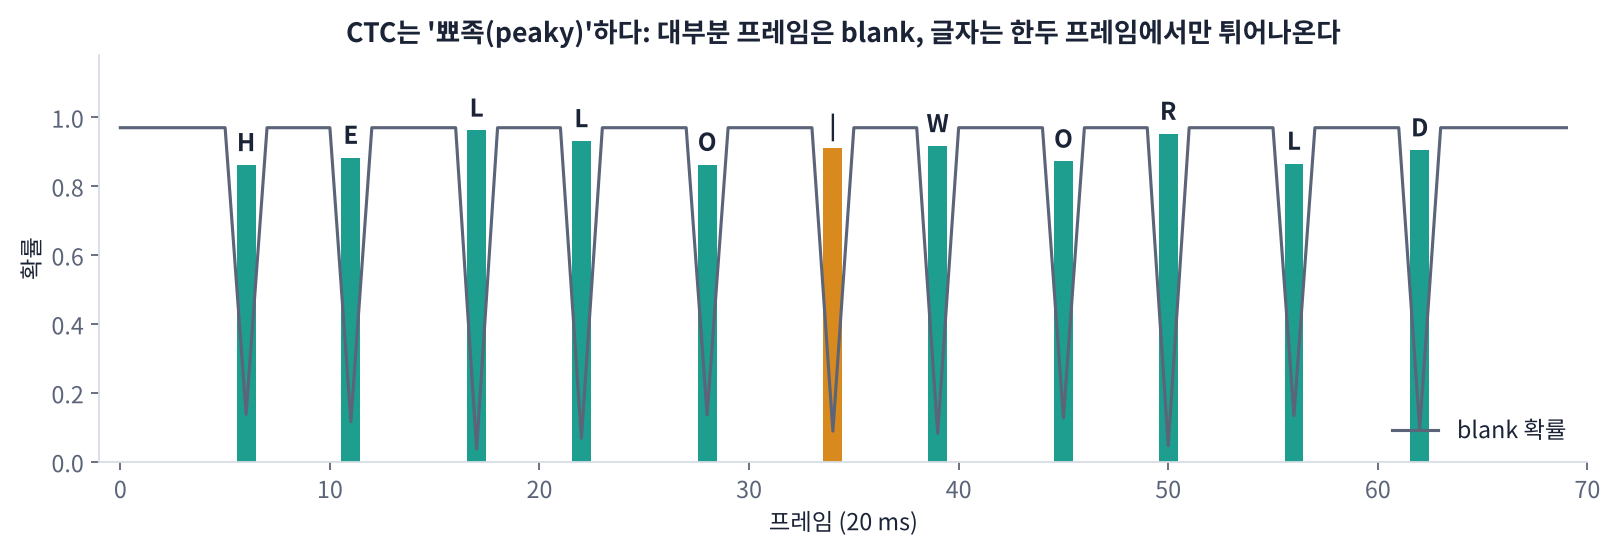

학습이 끝난 CTC 모델은 대부분의 프레임에서 **blank**를 내고, 글자는 **한두 프레임에서만 뾰족하게** 냅니다(peaky behavior). 정답 경로들의 합을 키우는 가장 쉬운 방법이 "확실한 순간에만 글자, 나머지는 blank"이기 때문입니다.

이 성질 덕분에 **글자가 튀어나온 프레임 번호 × 20 ms = 그 글자의 대략적인 시각**이 됩니다. 이것이 D9의 WhisperX 단어 정렬(wav2vec2 CTC 기반 forced alignment)의 출발점입니다.

### 🧩 빈칸 실습 5: 글자 · 단어 타임스탬프
새 글자가 나온 프레임 번호 `t`를 **초**로 바꾸세요. 한 프레임은 몇 초일까요? (`S_TOT`, `SR`을 쓰면 됩니다)

In [ ]:
# 🧩 빈칸 실습 5
FRAME_SEC = ____                                                   # 프레임 하나의 길이(초)

char_times = []                                                    # (글자, 시작 초)
for t, p in enumerate(path):
    if p != tok.pad_token and (t == 0 or p != path[t - 1]):        # 새 글자가 '튀어나온' 순간
        char_times.append((p, t * FRAME_SEC))

words, cur, start = [], "", None                                   # '|' 기준으로 단어 묶기
for ch, ts in char_times + [("|", len(path) * FRAME_SEC)]:
    if ch == tok.word_delimiter_token:
        if cur:
            words.append((cur, start, ts)); cur = ""
    else:
        if not cur: start = ts
        cur += ch
for w, s, e in words:
    print(f"{s:5.2f} ~ {e:5.2f} s  {w}")

fig, ax = plt.subplots(figsize=(13, 2.6))
ax.plot(np.arange(len(y_en)) / SR, y_en, lw=0.4, color="tab:cyan")
for w, s, e in words:
    ax.axvspan(s, e, alpha=0.15, color="tab:orange"); ax.text((s + e) / 2, 0.85 * np.abs(y_en).max(), w, ha="center", fontsize=10)
ax.set_xlabel("time (s)"); ax.set_title("word timestamps from CTC spikes"); plt.tight_layout(); plt.show()
check(np.isclose(FRAME_SEC, 0.02) and len(words) > 0 and words[-1][1] < len(y_en) / SR,
      hint="한 프레임 = 전체 보폭 320샘플 = 320 / 16000 초입니다.")

> ## 🎤 강사 스크립트 · 🧩 빈칸 5 타임스탬프  ⏱️ 7분
>
> 🎯 **스파이크 프레임 번호 × 0.02초 = 글자의 대략적인 시각 → 단어 타임스탬프.**
>
> 🆘 1단계: "프레임 하나는 몇 샘플 간격이었죠?" → 320
> 🆘 2단계: "320샘플은 몇 초?" → 320 / 16000
> 🆘 3단계: 정답 `S_TOT / SR` (0.02라고 숫자로 써도 정답 처리됨)
>
> ⚠️ `0.01`을 넣는 학생이 많습니다. D3 Log-Mel의 hop(10 ms)과 혼동한 것입니다.
>
> ✅ 예상 출력: 단어 6개(SPEECH, RECOGNITION, TURNS, SOUND, INTO, TEXT)와 시작 ~ 끝 초, 파형 위 주황 구간, `✅`
>
> 🗣️ "자막을 만들려면 '무슨 글자'뿐 아니라 '언제'가 필요합니다. CTC는 덤으로 시각을 줍니다. 다만 스파이크는 글자의 시작이 아니라 중간 어딘가일 수 있어 ±수십 ms 오차가 있습니다. 더 정확한 방법(forced alignment)은 D9 WhisperX에서 합니다."

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
FRAME_SEC = S_TOT / SR      # 320 / 16000 = 0.02
```

**해설**: Wav2Vec2 프레임은 20 ms마다 하나이므로 $t$번째 프레임은 $0.02\,t$초 근처입니다. 수용 영역이 25 ms라 실제로는 ±10 ms 정도 오차가 있고, 스파이크가 글자의 **시작이 아니라 중간 어딘가**에서 튀어나올 수 있다는 점도 기억하세요. 단어의 끝은 다음 `|`가 나온 시각으로 잡았습니다. 더 정확한 방법(forced alignment: 정답 글자를 알고 α처럼 가장 좋은 경로를 찾기)은 D9에서 합니다.

</details>

#### 🔍 코드 해설: Wav2Vec2 추론

| 코드 | 하는 일 |
|---|---|
| `Wav2Vec2Processor` | **특징 추출기**(파형을 평균 0, 분산 1로 정규화) + **토크나이저**(글자 ↔ 번호)를 하나로 묶은 것 |
| `processor(y, sampling_rate=16000, return_tensors="pt")` | `input_values` (1, L). 반드시 16 kHz. 다른 SR을 넣으면 오류 또는 엉뚱한 결과 |
| `w2v(input_values).logits` | (1, T, 32). softmax 전의 점수 |
| `tok.pad_token` = `<pad>` | **CTC blank 역할**. 번호 0 |
| `tok.word_delimiter_token` = `|` | 띄어쓰기를 글자 하나로 취급 |
| `processor.batch_decode(ids)` | 반복 합치기 → blank 지우기 → `|` → 공백. 빈칸 4와 같은 일 |

---
### 📝 2교시 마무리: 개념 워크시트

> **[worksheet.html 열기 → 2교시 탭](https://imguru-mooc.github.io/AI_Voice/day06/worksheet.html)** — Wav2Vec2 구조(CNN 7층 · Transformer · Linear), 보폭 320 · 수용 영역 400, 프레임 수 공식, `<pad>` = blank, `|` = 띄어쓰기, greedy 디코딩, CTC 스파이크, 타임스탬프 = 프레임 × 0.02 s
>
> 10문항을 풀고 **채점하기**를 누르세요. 결과 코드와 해설이 나옵니다. 채점 후에는 답이 잠깁니다. 제출은 4교시까지 모두 마친 뒤 한 번에 합니다.

> ## 🎤 강사 스크립트 · 2교시 마무리 → 3교시 도입  ⏱️ 5분 + 휴식
>
> 🖥️ [worksheet.html 2교시 탭](https://imguru-mooc.github.io/AI_Voice/day06/worksheet.html).
>
> 자주 틀리는 문항: **3번 1초 프레임 수**(49, 50이 아님), **9번 0.01초**(X).
>
> ➡️ (휴식 후) "CTC는 빠르고 단순하지만, 앞에서 무엇을 썼는지 모른 채 고릅니다. 'there'와 'their'처럼 소리가 같으면 문맥이 필요하죠. 이번에는 **앞 글자를 보며 쓰는** 방법입니다."

## Part 4. Attention Encoder-Decoder: 한 글자씩 생성하기

### 4-1. 📐 수식으로 보기: 조건부 독립을 버리다

CTC는 프레임끼리 독립이라고 가정해서, 앞에서 무엇을 썼는지 모른 채 글자를 고릅니다("their"와 "there"를 문맥으로 고르기 어려움). **AED**는 확률의 **연쇄 법칙**을 그대로 씁니다.

$$
P(Y \mid X) = \prod_{u=1}^{U} P(y_u \mid y_{<u}, X)
$$

- **Encoder**: 소리 전체 → $H = (h_1, \dots, h_T)$ (한 번만 계산)
- **Decoder**: 지금까지 쓴 글자 $y_{<u}$와 $H$를 보고 **다음 글자 하나**를 예측 (언어 모델처럼)
- **Cross-attention**: 디코더가 "지금 쓸 글자에 해당하는 소리 구간"을 $H$에서 찾아봄

$$
\text{Attention}(Q, K, V) = \text{softmax}\!\left(\frac{Q K^\top}{\sqrt{d_k}}\right) V
\qquad Q = \text{디코더 상태}, \; K = V = \text{인코더 출력 } H
$$

attention 가중치 $w_{u,t}$ (합 = 1)는 **"글자 $u$를 쓸 때 프레임 $t$를 얼마나 보았나"** 입니다. 학습이 잘 되면 이것이 대각선을 그리며 **정렬 역할**을 합니다. 즉, AED는 정렬을 경로의 합이 아니라 **attention으로 부드럽게** 배웁니다.

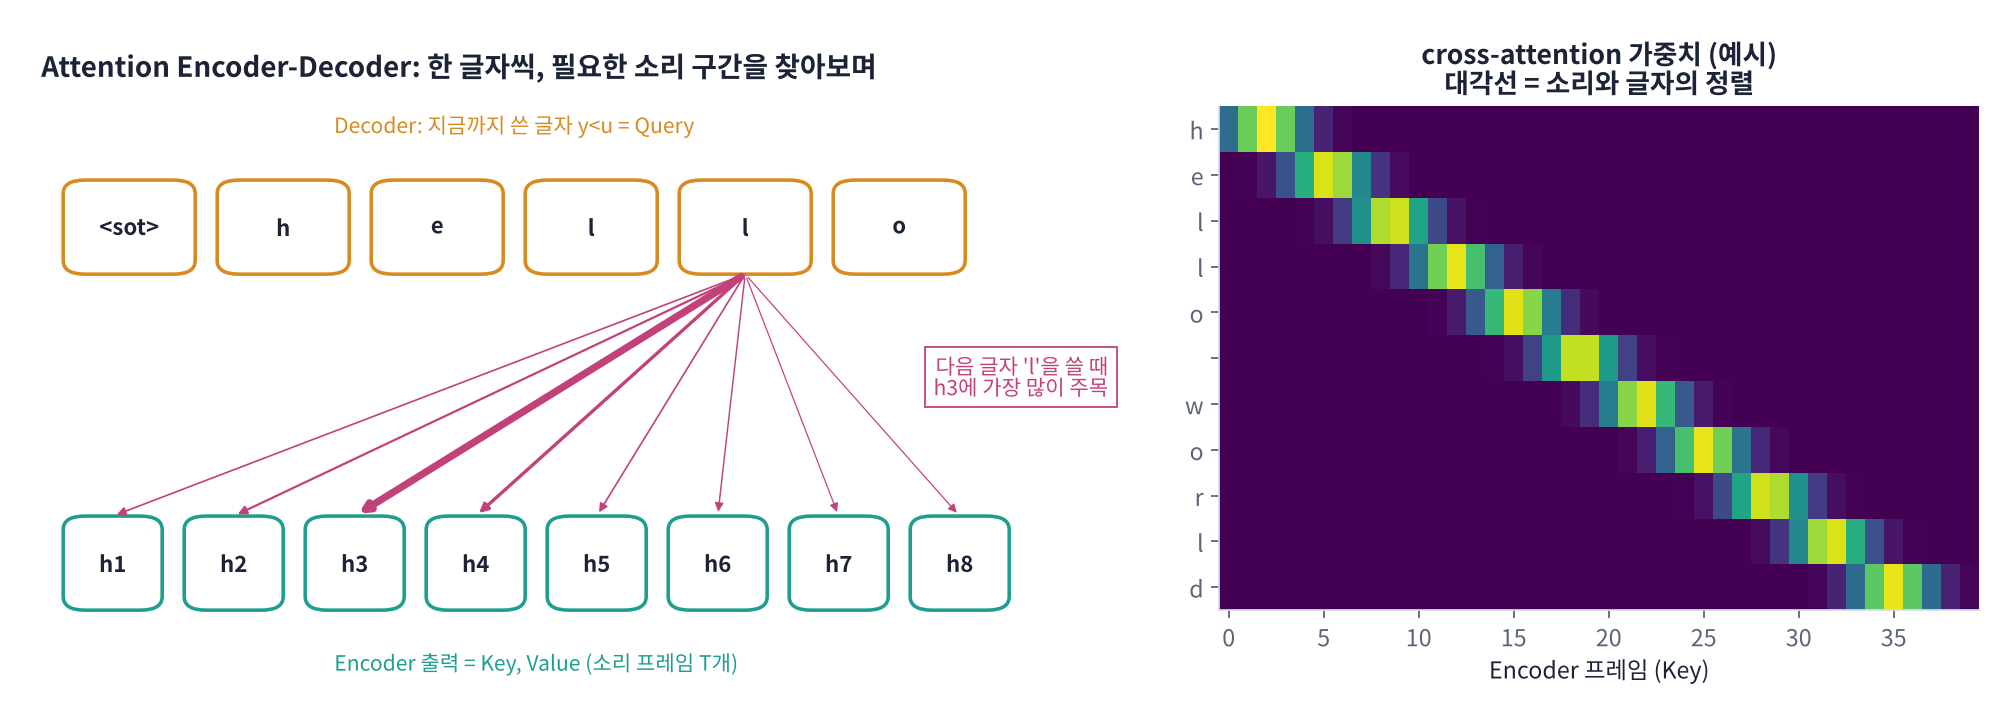

**$\sqrt{d_k}$로 나누는 이유**: $q, k$의 각 성분이 평균 0 · 분산 1이면 $q \cdot k = \sum_{i=1}^{d_k} q_i k_i$의 분산은 $d_k$입니다. 차원이 크면 점수가 너무 커져 softmax가 한 칸에 몰리고(포화) 기울기가 거의 0이 됩니다. $\sqrt{d_k}$로 나누면 분산이 1로 돌아옵니다.

> 🎬 **애니메이션 D6-6:** [Cross-attention 정렬](https://imguru-mooc.github.io/AI_Voice/day06/animation.html#attn) — 디코딩 한 걸음마다 어느 프레임을 보는지, √d 스케일 효과

> ## 🎤 강사 스크립트 · Part 4-1 Attention Encoder-Decoder  ⏱️ 8분
>
> 🎯 **AED = 소리 전체를 인코딩한 뒤, 앞 글자를 보며 한 토큰씩 생성. cross-attention이 정렬 역할.**
>
> 🖥️ 슬라이드 p.11 → 노트북 그림.
>
> 🗣️ "연쇄 법칙 P(y₁)P(y₂|y₁)P(y₃|y₁,y₂)… 그대로입니다. D5까지 배운 것으로 말하면, 매 걸음 '다음 글자 분류 문제'를 풉니다. 언어 모델(ChatGPT)이 다음 단어를 고르는 것과 같은 구조예요."
>
> 🍎 "속기사가 녹음을 다 들은 다음, 한 글자씩 적으면서 '지금 이 글자는 녹음의 어디쯤이었지?' 하고 되감아 듣는 것이 attention입니다."
>
> 🖥️ [D6-6 Cross-attention](https://imguru-mooc.github.io/AI_Voice/day06/animation.html#attn): '다음 토큰'을 한 번씩 눌러 분홍 막대(가중치)가 오른쪽으로 이동하고, 아래 행렬에 대각선이 쌓이는 것을 보여 줍니다. "이 대각선이 바로 정렬입니다. CTC처럼 강제로 순서를 정하지 않았는데도, 학습하면 저절로 대각선이 됩니다."
>
> 🗣️ (√d) "점수를 √d로 나누는 이유를 아래 슬라이더로 보겠습니다." → d=256에서 '√d로 나누기'를 껐다 켰다: 끄면 한 칸에 90% 이상 몰림.
>
> 🍎 "과목이 4개인 반과 400개인 반의 총점을 비교하면 안 되죠. 평균으로 맞춰야 합니다."

### 🧩 빈칸 실습 6: scaled dot-product attention
점수를 무엇으로 나눠야 할까요? 직접 구현한 결과를 PyTorch의 `F.scaled_dot_product_attention`과 비교합니다.

In [ ]:
# 🧩 빈칸 실습 6
def attention(Q, K, V):
    d = Q.shape[-1]
    scores = Q @ K.transpose(-2, -1) / ____             # (U, T) 글자 × 프레임
    w = scores.softmax(dim=-1)                          # 프레임 방향으로 합 = 1
    return w @ V, w

torch.manual_seed(0)
d = 64
Q = torch.randn(1, 5, d)                                # 디코더 쪽 5글자
K = torch.randn(1, 40, d); V = torch.randn(1, 40, d)    # 인코더 쪽 40프레임
out, w = attention(Q, K, V)
ref = F.scaled_dot_product_attention(Q, K, V)
print("출력 모양:", tuple(out.shape), "| 가중치 모양:", tuple(w.shape), "| 행 합:", w.sum(-1)[0].numpy().round(4))
print("PyTorch와 최대 차이:", (out - ref).abs().max().item())
check(torch.allclose(out, ref, atol=1e-5), hint="d_k의 제곱근 math.sqrt(d)로 나눕니다.")

> ## 🎤 강사 스크립트 · 🧩 빈칸 6 · 수식 검증 2  ⏱️ 6분
>
> 🆘 1단계: "수식 softmax(QKᵀ/√d_k)V에서 분모는?"
> 🆘 2단계: "`d`는 이미 있습니다. 제곱근 함수는 `math.sqrt`."
> 🆘 3단계: 정답 `math.sqrt(d)`
>
> ⚠️ `d`로 나누면 PyTorch와 차이가 나서 ❌. `d ** 0.5`도 정답입니다.
>
> ✅ 예상 출력: `출력 모양: (1, 5, 64) | 가중치 모양: (1, 5, 40) | 행 합: [1. 1. 1. 1. 1.]`, 최대 차이 1e-7 수준, `✅`
>
> 🖥️ 수식 검증 2: 표에서 d가 커질수록 '안 나눔'의 최대 가중치가 0.61 → 0.95로 커지고, '나눔'은 0.14로 일정한 것을 읽어 줍니다.

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
scores = Q @ K.transpose(-2, -1) / math.sqrt(d)
```

**해설**: $QK^\top$은 (5, 64) × (64, 40) = (5, 40), 즉 글자마다 40개 프레임에 대한 점수입니다. softmax는 **프레임 방향**(`dim=-1`)으로 해야 '글자 하나가 프레임들을 나눠 보는 비율'이 됩니다. `d`로 나누면 점수가 너무 작아져 가중치가 거의 균등해지고, 안 나누면 너무 커져 한 칸에 몰립니다.

</details>

In [ ]:
# ▶️ 수식 검증 2: q·k의 분산은 d, √d로 나누면 1 → softmax 포화를 막는다
for d_ in [16, 64, 256, 1024]:
    q, k = torch.randn(2000, d_), torch.randn(2000, 40, d_)
    raw = torch.einsum("nd,ntd->nt", q, k)
    print(f"d={d_:5d} | 점수 분산 {raw.var().item():7.1f} (이론 {d_}) | √d로 나눈 뒤 {(raw / math.sqrt(d_)).var().item():.2f} "
          f"| 최대 가중치 평균: 안 나눔 {raw.softmax(-1).max(-1).values.mean():.2f}, 나눔 {(raw / math.sqrt(d_)).softmax(-1).max(-1).values.mean():.2f}")

### 4-2. Whisper-tiny로 직접 확인하기

Whisper는 대표적인 AED 모델입니다(구조와 옵션은 **D7에서 깊게**). 오늘은 두 가지만 봅니다.
1. **한 글자(토큰)씩 생성하는 루프**를 직접 짜서 `generate()`와 같은 결과가 나오는지
2. **cross-attention**이 정말 소리와 글자를 정렬하는지

| 항목 | Whisper-tiny |
|---|---|
| 입력 | 80-mel Log-Mel, **30초로 패딩** → (1, 80, 3000), 10 ms hop |
| Encoder | Conv 2층(보폭 1, 2) → 1500 프레임(20 ms) → Transformer 4층 |
| Decoder | Transformer 4층, BPE 토큰(약 5만 개, 글자가 아니라 **조각 단어**) |
| 시작 토큰 | `<|startoftranscript|> <|en|> <|transcribe|> <|notimestamps|>` |

In [ ]:
from transformers import WhisperForConditionalGeneration, WhisperProcessor
from transformers.modeling_outputs import BaseModelOutput

WSP = "openai/whisper-tiny"
wproc = WhisperProcessor.from_pretrained(WSP)
whisper = WhisperForConditionalGeneration.from_pretrained(WSP, attn_implementation="eager").to(DEVICE).eval()   # eager: attention 가중치를 꺼내 보려고
wtok = wproc.tokenizer

feats = wproc(y_en, sampling_rate=SR, return_tensors="pt").input_features.to(DEVICE)      # (1, 80, 3000)
with torch.no_grad():
    gen = whisper.generate(feats, language="en", task="transcribe")
gen_text = wtok.batch_decode(gen, skip_special_tokens=True)[0]
print("입력 특징:", tuple(feats.shape), "| 파라미터", f"{sum(p.numel() for p in whisper.parameters()) / 1e6:.0f}M")
print("generate():", gen_text)
print("토큰:", wtok.convert_ids_to_tokens(gen[0].tolist()))

### 🧩 빈칸 실습 7: 한 토큰씩 생성하는 루프 (greedy)
디코더 출력 `logits`의 모양은 `(1, 지금까지 토큰 수, 어휘)`입니다. **다음 토큰**은 **마지막 위치**의 점수에서 고릅니다.

In [ ]:
# 🧩 빈칸 실습 7
prompt = ["<|startoftranscript|>", "<|en|>", "<|transcribe|>", "<|notimestamps|>"]
ids_w = torch.tensor([wtok.convert_tokens_to_ids(prompt)], device=DEVICE)
EOS = wtok.eos_token_id
suppress = list(whisper.generation_config.suppress_tokens or [])            # generate()와 같은 규칙: 쓰지 않는 토큰 막기
begin_suppress = list(whisper.generation_config.begin_suppress_tokens or [])

with torch.no_grad():
    enc = whisper.model.encoder(feats).last_hidden_state                   # (1, 1500, 384): 인코더는 한 번만
    for step in range(100):
        logits_w = whisper(encoder_outputs=BaseModelOutput(last_hidden_state=enc), decoder_input_ids=ids_w).logits
        nxt_scores = logits_w[0, ____].clone()                              # 다음 토큰 점수 (어휘 크기)
        nxt_scores[suppress] = -float("inf")
        if step == 0:
            nxt_scores[begin_suppress] = -float("inf")
        nxt = nxt_scores.argmax()
        ids_w = torch.cat([ids_w, nxt.view(1, 1)], dim=1)
        if nxt.item() == EOS:
            break

mine = wtok.batch_decode(ids_w, skip_special_tokens=True)[0]
print(f"내 루프({ids_w.shape[1] - len(prompt)} 걸음): {mine}")
print(f"generate()     : {gen_text}")
check(mine.strip() == gen_text.strip(), hint="다음 토큰은 마지막 위치 -1의 점수에서 고릅니다.")

> ## 🎤 강사 스크립트 · Part 4-2 Whisper · 🧩 빈칸 7  ⏱️ 12분
>
> 🎯 **인코더는 한 번, 디코더는 토큰마다 반복 = AED의 구조이자 약점.**
>
> 🗣️ (generate 셀) "Whisper-tiny는 3,900만 파라미터짜리 가장 작은 Whisper입니다. 출력 토큰을 보면 글자가 아니라 'Ġspeech' 같은 **조각 단어(BPE)** 입니다. Ġ는 앞에 띄어쓰기가 있다는 표시예요."
>
> 🆘 빈칸 7: 1단계 "logits_w 모양은 (1, 지금까지 토큰 수, 어휘)입니다. 위치마다 '그다음 토큰' 예측이 들어 있어요." 2단계 "지금 필요한 건 가장 최근 토큰 다음, 즉 몇 번 위치?" → 마지막. 정답 `-1`.
>
> ✅ 예상 출력: `내 루프(약 8~10 걸음): Speech recognition turns sound into text.` 와 generate() 결과가 같고 `✅`
>
> ⚠️ 만약 ❌인데 내용이 거의 같다면 transformers 버전 차이로 특수 토큰 처리가 다른 경우입니다. 내용이 같으면 정답으로 인정해 주세요.
>
> 🖥️ cross-attention 그림: "행이 토큰, 열이 소리 프레임. 대각선이 보이죠? Whisper가 단어 타임스탬프를 만들 때 이 그림을 씁니다(D7, D9)."
>
> 🗣️ "이 루프의 약점: 한 번 틀린 토큰이 다음 입력이 됩니다. 그래서 같은 말을 반복하거나, 없는 말을 지어내는 **환각**이 생깁니다. 내일 D7의 주제입니다."

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
nxt_scores = logits_w[0, -1].clone()
```

**해설**: 디코더는 위치마다 '그다음 토큰' 점수를 내므로, 지금 필요한 것은 **마지막 위치(-1)** 하나입니다. 걸음마다 디코더를 처음부터 다시 돌리는 것은 느리기 때문에 `generate()`는 이전 계산을 저장해 두는 **KV 캐시**를 씁니다(결과는 같음). 이 루프가 AED의 핵심이자 약점입니다: 출력 길이만큼 디코더를 돌려야 하고, 한 번 잘못 고른 토큰이 다음 입력이 되어 **반복 · 환각**으로 번질 수 있습니다(D7).

</details>

In [ ]:
# cross-attention으로 정렬 보기: Whisper가 '정렬용'으로 고른 헤드(alignment_heads)의 평균
with torch.no_grad():
    out_w = whisper(encoder_outputs=BaseModelOutput(last_hidden_state=enc), decoder_input_ids=ids_w, output_attentions=True)
ca = torch.stack(out_w.cross_attentions)[:, 0]                          # (층, 헤드, 토큰 수, 1500)
heads = whisper.generation_config.alignment_heads or [[ca.shape[0] - 1, h] for h in range(ca.shape[1])]
A = torch.stack([ca[l, h] for l, h in heads]).mean(0).cpu().numpy()   # (토큰 수, 1500)

n_aud = int(len(y_en) / SR / 0.02) + 10                                 # 실제 소리가 있는 프레임까지만
toks = wtok.convert_ids_to_tokens(ids_w[0].tolist())
rows = list(range(len(prompt) - 1, len(toks) - 1))                      # 위치 u의 출력 = 토큰 u+1
A_show = A[rows, :n_aud]
A_show = (A_show - A_show.mean(0)) / (A_show.std(0) + 1e-6)             # 프레임마다 표준화 → 대각선이 잘 보이게
fig, ax = plt.subplots(figsize=(12, 4))
ax.imshow(A_show, aspect="auto", cmap="viridis")
ax.set_yticks(range(len(rows))); ax.set_yticklabels([toks[u + 1].replace("Ġ", "_") for u in rows])
ax.set_xlabel("encoder frame (20 ms)"); ax.set_title("Whisper cross-attention: token (row) x audio frame (col)")
plt.tight_layout(); plt.show()

#### 🔍 코드 해설: Whisper 디코딩과 attention

| 코드 | 하는 일 |
|---|---|
| `attn_implementation="eager"` | 기본(sdpa)은 빠르지만 attention 가중치를 돌려주지 않음. 가중치를 보려면 eager |
| `wproc(y, sampling_rate=16000).input_features` | 80-mel Log-Mel, **30초로 패딩**해 항상 (1, 80, 3000) |
| `whisper.model.encoder(feats)` | 인코더만 실행 → (1, 1500, 384). 디코딩 중에는 다시 계산할 필요 없음 |
| `decoder_input_ids` | 지금까지의 토큰. 첫 4개는 작업 지시(언어 · 받아쓰기 · 타임스탬프 없음) |
| `suppress_tokens` | 받아쓰기에 쓰지 않는 기호 토큰을 −∞로. `generate()`도 똑같이 함 |
| `output_attentions=True` → `cross_attentions` | 층마다 (1, 헤드, 토큰 수, 1500) |
| `generation_config.alignment_heads` | OpenAI가 '정렬이 잘 나오는' 헤드를 골라 둔 목록. 단어 타임스탬프 계산에 씀 (D7 · D9) |

## Part 5. Transducer (RNN-T): 스트리밍을 위한 방법

### 5-1. 📐 수식으로 보기: $T \times (U+1)$ 격자

AED는 소리 **전체**를 인코딩한 뒤에야 첫 글자를 씁니다. 그래서 말하는 도중에 자막을 띄우는 **스트리밍**에 불리합니다. CTC는 스트리밍이 되지만 앞 글자를 보지 못합니다. **Transducer**(Graves 2012)는 둘의 장점을 합칩니다.

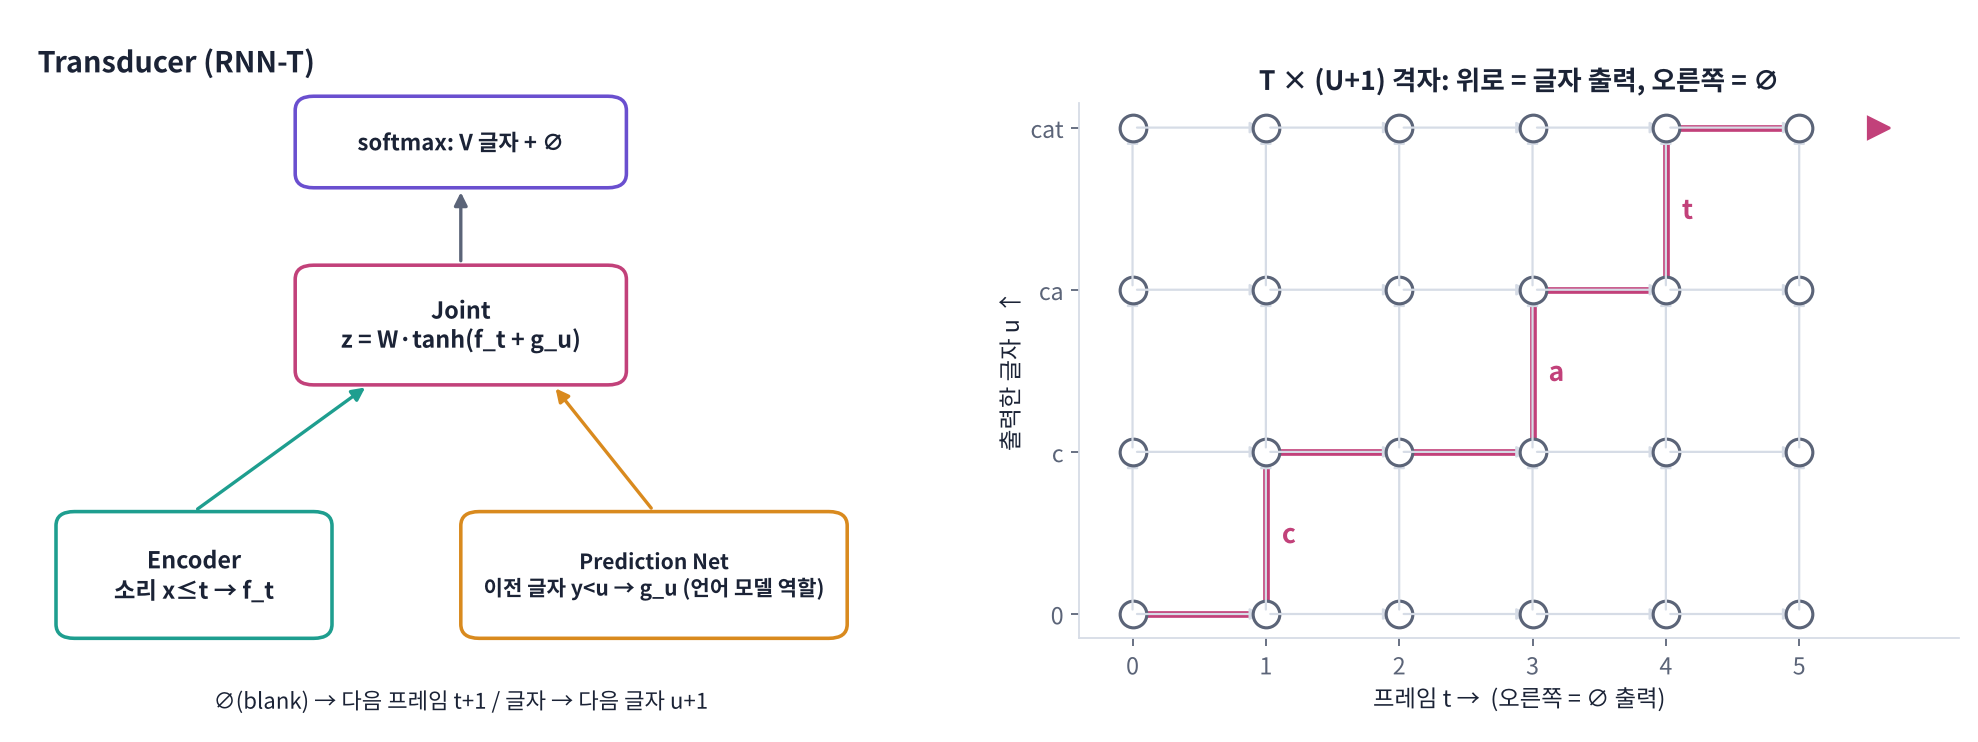

- **Encoder**: 지금까지의 소리 $x_{\le t}$ → $f_t$ (미래를 보지 않게 만들 수 있어 스트리밍 가능)
- **Prediction network**: 지금까지 낸 글자 $y_{\le u}$ → $g_u$ (언어 모델 역할, CTC에 없는 부분)
- **Joint network**: $z_{t,u} = W \tanh(f_t + g_u)$ → softmax over **글자 + ∅(blank)**

격자의 점 $(t, u)$ = "프레임 $t$를 보고 있고, 글자를 $u$개 냈다". 한 걸음마다
- **∅** 를 내면 → $(t+1, u)$ 오른쪽으로 (다음 프레임)
- **글자 $y_{u+1}$** 를 내면 → $(t, u+1)$ 위로 (같은 프레임에서 여러 글자도 가능)

$$
\alpha(t, u) = \alpha(t-1, u)\, \varnothing(t-1, u) \;+\; \alpha(t, u-1)\, y(t, u-1), \qquad \alpha(0, 0) = 1
$$
$$
P(Y \mid X) = \alpha(T-1, U)\, \varnothing(T-1, U)
$$

여기서 $\varnothing(t,u)$, $y(t,u)$는 점 $(t,u)$에서 각각 blank, 다음 정답 글자 $y_{u+1}$을 낼 확률입니다. 경로는 정확히 $T$번의 ∅와 $U$번의 글자로 이뤄지고, 마지막 걸음은 ∅이므로 경로 수는 $\binom{T+U-1}{U}$입니다.

> 🎬 **애니메이션 D6-7:** [Transducer 격자](https://imguru-mooc.github.io/AI_Voice/day06/animation.html#rnnt) — 격자를 한 걸음씩 걸으며 ∅ · 글자 출력, α 채우기

> ## 🎤 강사 스크립트 · Part 5-1 Transducer  ⏱️ 8분
>
> 🎯 **Transducer = CTC처럼 프레임 단위로 들으면서(스트리밍), AED처럼 앞 글자를 본다. 격자에서 ∅는 오른쪽, 글자는 위.**
>
> 🗣️ "AED는 말이 다 끝나야 시작합니다. 화상회의 실시간 자막에는 못 쓰죠. CTC는 실시간은 되지만 앞 글자를 못 봅니다. 휴대폰 받아쓰기는 둘 다 필요합니다. 그래서 나온 것이 Transducer입니다."
>
> 🍎 "실시간 속기사: 들으면서 바로 적고, 앞에 쓴 글자를 보며 다음 글자를 정하고, 이번 사진에서 더 쓸 게 없으면 '다음'(∅)이라고 말합니다."
>
> 🖥️ [D6-7 Transducer 격자](https://imguru-mooc.github.io/AI_Voice/day06/animation.html#rnnt): cat, T=5.
> 1. '글자 ↑'를 세 번 눌러 t=0에서 c, a, t를 다 내 보기 → "한 프레임에서 여러 글자 가능!"
> 2. 처음으로 → '∅ →'만 계속 누르면 마지막 프레임에서 막힘 → "남은 글자를 다 내야 끝낼 수 있습니다."
> 3. 🎲 무작위로 걷기 → 끝나면 경로 수 C(7, 3) = 35.
>
> ❓ "CTC 격자와 무엇이 다른가요?" → CTC는 매 프레임 한 칸(글자 또는 blank)을 반드시 내고 다음 프레임으로 감. Transducer는 위로(글자)와 오른쪽(∅)이 분리됨.

### 🧩 빈칸 실습 8: RNN-T α 점화식 (log 공간)
위쪽에서 오는 경로는 점 $(t, u-1)$에서 **$u$번째 정답 글자**를 낸 것입니다. 정답 글자 배열 `y`(0번부터)에서 몇 번 칸일까요? (확률 곱 대신 log 합, 덧셈 대신 `logaddexp`를 씁니다)

In [ ]:
# 🧩 빈칸 실습 8
def rnnt_forward(logp, y, blank=0):
    # logp: (T, U+1, V) 격자 각 점에서의 log 확률, y: 정답 글자 번호 (길이 U)
    T, U1, _ = logp.shape
    alpha = np.full((T, U1), -np.inf)
    alpha[0, 0] = 0.0
    for t in range(T):
        for u in range(U1):
            if t == 0 and u == 0:
                continue
            a = -np.inf
            if t > 0:                                   # 왼쪽 (t-1, u)에서 ∅를 내고 옴
                a = np.logaddexp(a, alpha[t - 1, u] + logp[t - 1, u, blank])
            if u > 0:                                   # 아래 (t, u-1)에서 글자를 내고 옴
                a = np.logaddexp(a, alpha[t, u - 1] + logp[t, u - 1, y[____]])
            alpha[t, u] = a
    return alpha, alpha[T - 1, U1 - 1] + logp[T - 1, U1 - 1, blank]

rng = np.random.default_rng(1)
T5, y5, V5 = 5, [2, 1, 3], 4                                   # 프레임 5개, 정답 3글자, 어휘 = ∅ + 3글자
z = rng.normal(size=(T5, len(y5) + 1, V5))
logp5 = z - np.log(np.exp(z).sum(-1, keepdims=True))           # log_softmax

def rnnt_brute(logp, y, blank=0):                              # 정답: 모든 경로를 직접 나열해 더하기
    T, U1, _ = logp.shape; U = U1 - 1; tot = -np.inf; n = 0
    for pos in itertools.combinations(range(T + U - 1), U):    # 마지막 걸음(∅)을 뺀 T+U-1걸음 중 글자 위치
        t = u = 0; lp = 0.0
        for k in range(T + U - 1):
            if k in pos: lp += logp[t, u, y[u]]; u += 1
            else:        lp += logp[t, u, blank]; t += 1
        tot = np.logaddexp(tot, lp + logp[t, u, blank]); n += 1
    return tot, n

_, ll = rnnt_forward(logp5, y5)
bl, n_paths = rnnt_brute(logp5, y5)
print(f"log P: α 점화식 {ll:.6f} | 경로 {n_paths}개 전부 더하기 {bl:.6f} (공식 C(T+U-1, U) = {math.comb(T5 + 2, 3)})")
check(np.isclose(ll, bl), hint="점 (t, u-1)에서 내는 글자는 u번째 글자, 0부터 세면 y[u - 1]입니다.")

> ## 🎤 강사 스크립트 · 🧩 빈칸 8 · 수식 검증 3  ⏱️ 6분
>
> 🆘 1단계: "점 (t, u−1)은 '글자를 몇 개 낸 상태'?" → u−1개
> 🆘 2단계: "그다음에 낼 글자는 몇 번째 글자? 파이썬은 0부터 셉니다."
> 🆘 3단계: 정답 `u - 1`
>
> ✅ 예상 출력: `log P: α 점화식 … | 경로 35개 전부 더하기 …` 같은 값, `✅`, 수식 검증 3에서 torchaudio 값과 같음(또는 '쓸 수 없는 환경' 안내)
>
> ⚠️ torchaudio 2.9 이후 일부 기능이 정리되면서 `rnnt_loss`가 없을 수 있습니다. 그 경우 안내 문구가 나오고 넘어가면 됩니다.
>
> 🗣️ "경로 수를 비교해 보면 둘 다 천문학적이지만, 둘 다 α로 T×U번 계산이면 끝납니다. 오늘 배운 α 하나로 CTC와 Transducer가 다 설명됩니다."

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
a = np.logaddexp(a, alpha[t, u - 1] + logp[t, u - 1, y[u - 1]])
```

**해설**: 점 $(t, u-1)$은 '글자를 $u-1$개 냈다'는 뜻이므로 다음에 낼 글자는 $y_u$, 파이썬 0번 인덱스로는 `y[u - 1]`입니다. CTC의 α와 비교하면, CTC는 **매 프레임 정확히 한 칸**(글자 또는 blank)을 내지만, Transducer는 **한 프레임에서 글자를 여러 개** 낼 수 있고 프레임을 넘어갈 때만 ∅를 냅니다. 그래서 $T < U$여도 됩니다.

</details>

In [ ]:
# ▶️ 수식 검증 3: torchaudio의 RNN-T 손실과 비교 (torchaudio 버전에 따라 없을 수 있음)
try:
    import torchaudio.functional as AF
    loss_ta = AF.rnnt_loss(torch.tensor(logp5, dtype=torch.float32)[None], torch.tensor([y5], dtype=torch.int32),
                           torch.tensor([T5], dtype=torch.int32), torch.tensor([len(y5)], dtype=torch.int32),
                           blank=0, reduction="sum")
    print(f"−log P: 내 구현 {-ll:.5f} | torchaudio.functional.rnnt_loss {loss_ta.item():.5f}")
except Exception as e:
    print("torchaudio rnnt_loss를 쓸 수 없는 환경입니다 → 위의 '전부 더하기' 비교로 충분합니다.", type(e).__name__)

# 경로 수 비교: CTC vs Transducer (실제 크기)
for T_, U_ in [(50, 10), (150, 40)]:
    print(f"T={T_}, U={U_}: CTC C(T+U, 2U) ≈ 10^{math.log10(math.comb(T_ + U_, 2 * U_)):.0f}, "
          f"Transducer C(T+U-1, U) ≈ 10^{math.log10(math.comb(T_ + U_ - 1, U_)):.0f}  → 둘 다 α(동적 계획법)로 O(T·U)")

### 5-2. 세 방식 비교

| | **CTC** | **Attention Enc-Dec** | **Transducer (RNN-T)** |
|---|---|---|---|
| $P(Y \mid X)$ | $\sum_\pi \prod_t p_t(\pi_t)$ | $\prod_u P(y_u \mid y_{<u}, X)$ | $\sum_{\text{격자 경로}} \prod P(\cdot \mid t, u)$ |
| 앞 글자를 보나 | ✗ (조건부 독립) | ✓ | ✓ (prediction net) |
| 정렬 | 경로 합 (단조, 강제) | attention (부드러움, 강제 아님) | 경로 합 (단조, 강제) |
| 출력 길이 | $U \le T$ | 제한 없음 | 제한 없음 |
| 스트리밍 | 쉬움 | 어려움 (전체 입력 필요) | **쉬움 — 설계 목적** |
| 디코딩 속도 | 가장 빠름 (한 번에) | 느림 (토큰마다 디코더) | 중간 |
| 흔한 실패 | 철자 실수, 동음이의어 | 반복 · 환각, 긴 입력 | 학습 메모리 큼 ($T \times U \times V$) |
| 대표 | Wav2Vec2, HuBERT 미세조정 | Whisper | Conformer-Transducer, 휴대폰 받아쓰기 |

> 💡 실무에서는 **CTC + Attention을 함께 학습**(하이브리드)하거나, **CTC로 빠르게 + AED로 다시 점수 매기기**를 많이 씁니다. 오늘 배운 세 손실은 서로 경쟁자라기보다 **도구 상자**입니다.

> 🎬 **애니메이션 D6-8:** [세 방식 비교](https://imguru-mooc.github.io/AI_Voice/day06/animation.html#compare) — 같은 문장을 세 방식으로 출력하는 타이밍(스트리밍) 비교

> ## 🎤 강사 스크립트 · Part 5-2 세 방식 비교  ⏱️ 5분
>
> 🖥️ [D6-8 세 방식 비교](https://imguru-mooc.github.io/AI_Voice/day06/animation.html#compare): '말하기' → CTC · Transducer 줄은 말하는 중에 글자가 차오르고, AED 줄은 '말 끝' 선을 넘어야 시작. '느린 기기'를 켜면 AED만 더 늦어지는 것도 보여 줍니다.
>
> ❓ "콜센터에서 상담 중 실시간 자막과, 통화 후 정확한 녹취록. 각각 무엇을?" → 실시간 = CTC 또는 Transducer, 녹취록 = AED(Whisper)도 좋은 후보. (과제 3과 연결)
>
> 🗣️ "셋은 경쟁자라기보다 도구 상자입니다. 실무에서는 CTC와 Attention을 같이 학습하기도 하고, CTC로 빨리 후보를 내고 AED로 다시 점수를 매기기도 합니다."

---
### 📝 3교시 마무리: 개념 워크시트

> **[worksheet.html 열기 → 3교시 탭](https://imguru-mooc.github.io/AI_Voice/day06/worksheet.html)** — 연쇄 법칙 $\prod_u P(y_u \mid y_{<u}, X)$, encoder · decoder · cross-attention, $\text{softmax}(QK^\top/\sqrt{d_k})V$, 한 토큰씩 생성 루프, alignment heads, Transducer 격자, ∅ = 다음 프레임, α 점화식, 스트리밍 비교
>
> 10문항을 풀고 **채점하기**를 누르세요. 결과 코드와 해설이 나옵니다. 채점 후에는 답이 잠깁니다. 제출은 4교시까지 모두 마친 뒤 한 번에 합니다.

> ## 🎤 강사 스크립트 · 3교시 마무리 → 4교시 도입  ⏱️ 5분 + 휴식
>
> 🖥️ [worksheet.html 3교시 탭](https://imguru-mooc.github.io/AI_Voice/day06/worksheet.html).
>
> 자주 틀리는 문항: **2번 Q · K · V** (Q = 디코더), **9번 경로 수 35**, **8번 순서 맞추기**(인코더가 먼저).
>
> ➡️ (휴식 후) "오늘 쓴 Wav2Vec2 모델 이름에 '960h'가 붙어 있었죠. 그런데 그 모델은 받아쓰기를 배우기 **전에** 라벨 없는 음성으로 먼저 공부했습니다. 마지막 교시는 그 '선행 학습' 이야기입니다."

## Part 6. 자기지도 학습: 라벨 없이 소리를 먼저 배우기

### 6-1. 왜 필요한가

받아쓰기 라벨은 비쌉니다(1시간 음성을 받아 적는 데 몇 시간). 반면 **라벨 없는 음성**은 거의 무한합니다. 그래서 두 단계로 나눕니다.

1. **사전학습**(self-supervised): 라벨 없는 음성 수만 시간으로 "소리를 잘 표현하는" 인코더 만들기
2. **미세조정**(fine-tuning): 그 위에 Linear + CTC를 붙여 **적은 라벨**로 받아쓰기 학습 (Part 3의 모델이 이것)

wav2vec 2.0 논문(2020)에서는 라벨 **10분**만으로도 LibriSpeech 받아쓰기가 동작했습니다. 한국어처럼 라벨이 적은 언어에서 특히 중요합니다(3주차).

### 6-2. 📐 수식으로 보기: wav2vec 2.0 — 마스킹 · 양자화 · 대조 손실

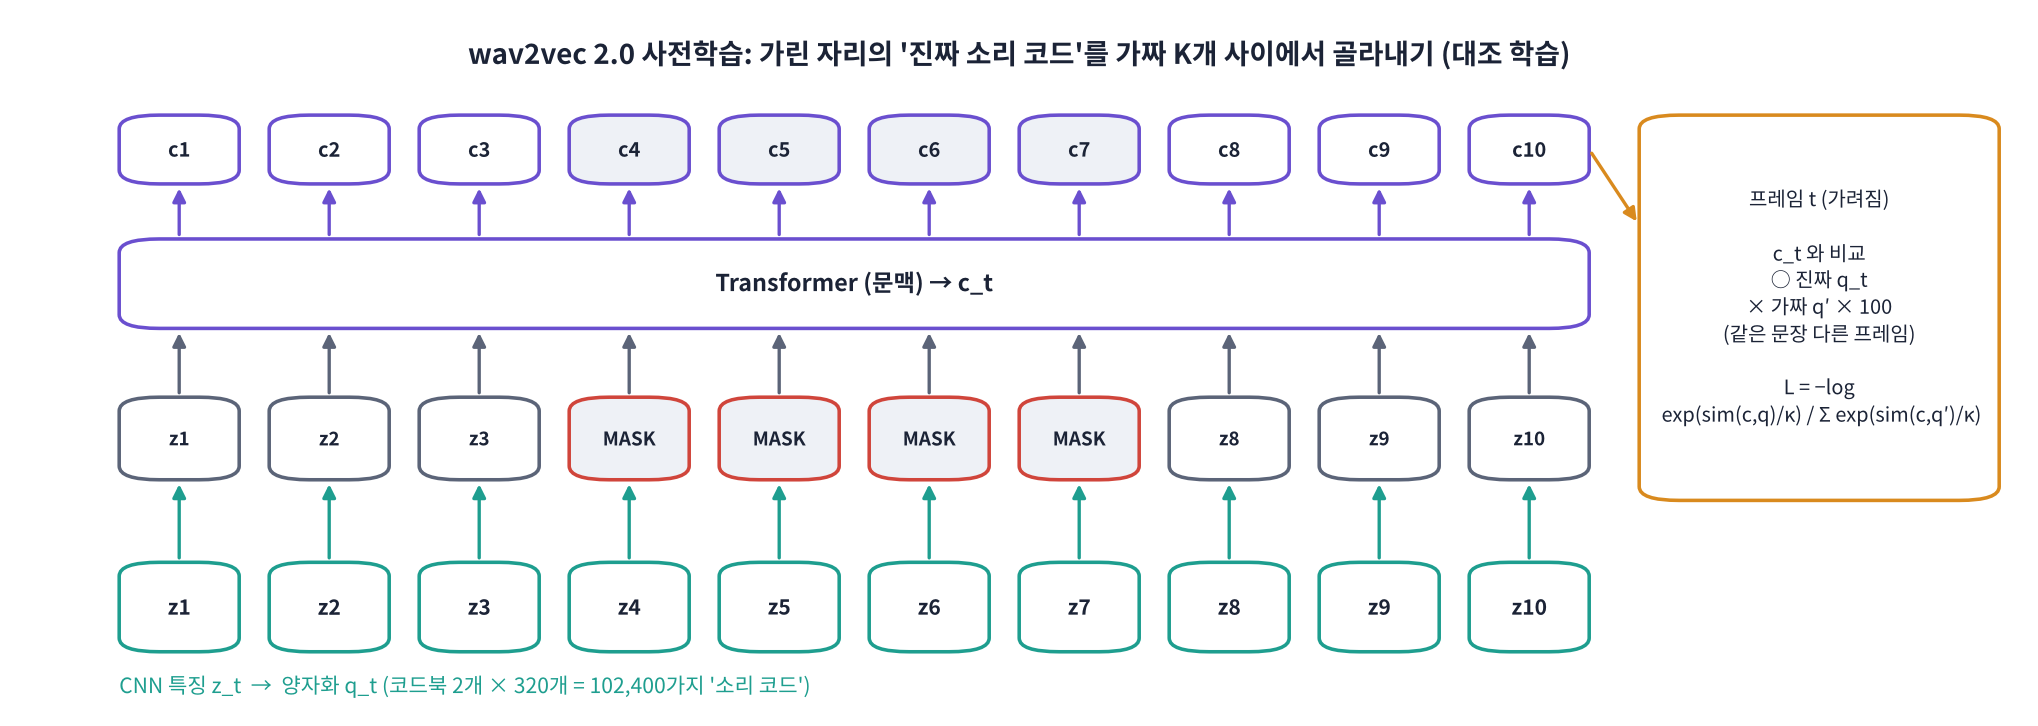

**① 마스킹**: CNN 특징 $z_t$에서 프레임마다 확률 $p = 0.065$로 '시작점'을 뽑고, 거기서부터 $M = 10$ 프레임을 가립니다. 한 프레임이 가려질 확률은 (앞쪽 $M$개 중 하나라도 시작점일 확률)

$$
P(\text{가려짐}) = 1 - (1 - p)^{M} = 1 - 0.935^{10} \approx 0.49
$$

**② 양자화**: 가리기 전의 $z_t$를 **코드북**에서 가장 가까운 '소리 코드' $q_t$로 바꿉니다. 코드북 $G = 2$개 × 항목 $V = 320$개 → $320^2 = 102{,}400$가지 조합. 고르는 동작은 미분이 안 되므로 **Gumbel-softmax**로 근사합니다.

**③ 대조 손실 (InfoNCE)**: 가려진 자리 $t$에서 Transformer 출력 $c_t$가 **진짜 $q_t$** 를 같은 문장의 다른 프레임에서 뽑은 **가짜 $K = 100$개** 사이에서 골라내야 합니다.

$$
\mathcal{L}_m = -\log \frac{\exp(\text{sim}(c_t, q_t)/\kappa)}{\sum_{\tilde q \,\in\, \{q_t\} \cup Q_t^{-}} \exp(\text{sim}(c_t, \tilde q)/\kappa)},
\qquad \text{sim}(a, b) = \frac{a \cdot b}{\|a\| \|b\|}, \; \kappa = 0.1
$$

D5의 **softmax + cross-entropy와 똑같은 모양**입니다. '클래스'가 고정된 단어 10개가 아니라 **매번 새로 뽑은 후보 101개**이고, 정답이 항상 0번 칸(진짜)이라는 점만 다릅니다. (코드북을 골고루 쓰게 하는 다양성 손실 $\mathcal{L}_d$도 더합니다: $\mathcal{L} = \mathcal{L}_m + 0.1\,\mathcal{L}_d$)

> 🎬 **애니메이션 D6-9:** [자기지도 학습](https://imguru-mooc.github.io/AI_Voice/day06/animation.html#ssl) — 마스킹 확률 · 길이 슬라이더, 진짜/가짜 코드 고르기, HuBERT 클러스터

> ## 🎤 강사 스크립트 · Part 6-1 ~ 6-2 wav2vec 2.0  ⏱️ 10분
>
> 🎯 **라벨 없이: 가리고 → 가려진 자리의 진짜 소리 코드를 가짜 100개 사이에서 고르기 (InfoNCE).**
>
> 🗣️ "받아쓰기 라벨 1시간을 만들려면 사람이 몇 시간 들어야 합니다. 라벨 없는 음성은 유튜브, 라디오에 무한히 있습니다. 그래서 먼저 라벨 없이 '귀를 트이게' 하고, 마지막에 적은 라벨로 받아쓰기만 가르칩니다."
>
> 🍎 "영어 듣기 시험에서 중간에 '삐-' 소리로 가려진 부분을 앞뒤 문맥으로 맞히는 연습을 생각하세요. 정답 대신 '보기 101개 중 진짜 고르기'로 바꾼 것이 대조 학습입니다."
>
> 🖥️ [D6-9 ①](https://imguru-mooc.github.io/AI_Voice/day06/animation.html#ssl): p = 0.065, M = 10에서 약 49%. p를 두 배로 하면 70% 넘게 가려지는 것도 보여 줍니다.
>
> 🗣️ (수식) "InfoNCE를 자세히 보면 D5에서 쓴 softmax + cross-entropy와 똑같습니다. 차이는 정답 칸이 항상 0번이고, '클래스'가 매번 새로 뽑은 101개라는 것뿐입니다."
>
> 🖥️ D6-9 ②: 진짜의 유사도를 낮추면 손실이 커지고, κ를 1로 키우면 진짜가 이겨도 확률이 낮게 나오는 것.
>
> ✅ 수식 검증 4 예상 출력: 공식 0.489 ≈ 시뮬레이션 0.49

In [ ]:
# ▶️ 수식 검증 4: 가려지는 비율 1 − (1 − p)^M
rng = np.random.default_rng(0)
L_, trials = 500, 2000
for p, M in [(0.065, 10), (0.065, 5), (0.03, 10)]:
    starts = rng.random((trials, L_)) < p                                   # 시작점 뽑기
    masked = np.zeros_like(starts)
    for k in range(M):                                                      # 시작점부터 M칸 가리기
        masked[:, k:] |= starts[:, :L_ - k]
    print(f"p={p}, M={M:2d} | 공식 {1 - (1 - p) ** M:.3f} | 시뮬레이션 {masked[:, M:].mean():.3f}")

### 🧩 빈칸 실습 9: InfoNCE 대조 손실
후보 101개 중 **0번 칸이 진짜** $q_t$입니다. log-softmax에서 몇 번 칸을 꺼내 −평균하면 될까요? `F.cross_entropy`와 같아야 합니다.

In [ ]:
# 🧩 빈칸 실습 9
torch.manual_seed(0)
T_, K_, D_, kappa = 8, 100, 256, 0.1
c = torch.randn(T_, D_)                                        # Transformer 출력 c_t (가려진 자리 8개)
q_pos = c + 3.0 * torch.randn(T_, D_)                          # 진짜 q_t: c_t와 조금 닮음 (잡음이 큼)
q_neg = torch.randn(T_, K_, D_)                                # 가짜 100개
cands = torch.cat([q_pos.unsqueeze(1), q_neg], dim=1)          # (T, 1+K, D) — 0번 칸 = 진짜
sims = F.cosine_similarity(c.unsqueeze(1), cands, dim=-1)      # (T, 1+K)

loss_manual = -torch.log_softmax(sims / kappa, dim=-1)[:, ____].mean()
loss_ce = F.cross_entropy(sims / kappa, torch.zeros(T_, dtype=torch.long))
acc = (sims.argmax(-1) == 0).float().mean()
print(f"InfoNCE 직접 {loss_manual.item():.4f} | F.cross_entropy {loss_ce.item():.4f} | 진짜를 1등으로 고른 비율 {acc:.0%}")
print(f"참고: 무작위로 고르면 손실 log(101) = {math.log(101):.3f}")
for k in [1.0, 0.1, 0.01]:
    print(f"  κ = {k:5}: 손실 {F.cross_entropy(sims / k, torch.zeros(T_, dtype=torch.long)).item():.3f}")
check(torch.allclose(loss_manual, loss_ce), hint="진짜는 0번 칸입니다.")

> ## 🎤 강사 스크립트 · 🧩 빈칸 9 · 6-3 사전학습 모델  ⏱️ 8분
>
> 🆘 1단계: "cands를 만들 때 진짜를 어디에 붙였나요? `torch.cat([q_pos..., q_neg])`"
> 🆘 2단계: "맨 앞 = 몇 번 칸?"
> 🆘 3단계: 정답 `0`
>
> ✅ 예상 출력: `InfoNCE 직접 1.6xx | F.cross_entropy 1.6xx | 진짜를 1등으로 고른 비율 100%`, κ가 1.0 → 0.1 → 0.01일 때 손실 4.3 → 1.6 → 0.0, `✅`
>
> 🖥️ (6-3 셀, 시간이 부족하면 강사만 시연) "진짜 wav2vec2-base 체크포인트에 우리 문장을 넣고 가렸습니다. 진짜 코드와의 유사도가 가짜보다 확실히 높고, 100개 중 1등으로 고르는 비율이 무작위(1%)보다 훨씬 높습니다. 라벨 없이 이걸 배운 겁니다."
>
> ⚠️ 💡 박스: transformers의 `mask_prob=0.65`는 논문의 0.065가 아닙니다. p × M입니다. 워크시트 4교시 9번 문항.

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
loss_manual = -torch.log_softmax(sims / kappa, dim=-1)[:, 0].mean()
```

**해설**: 정답 클래스 번호가 항상 0인 cross-entropy입니다. 코사인 유사도는 $-1 \sim 1$이라 그대로 softmax하면 차이가 작으므로 **온도 $\kappa$** 로 나눠 키웁니다. $\kappa$가 작을수록 '진짜와 비슷한 가짜'를 더 세게 밀어냅니다. 너무 작으면 학습이 불안정하고, 너무 크면 구분을 덜 하게 되어 논문은 0.1을 썼습니다.

</details>

### 6-3. 실제 wav2vec2-base(사전학습만 한 모델)로 확인하기

`facebook/wav2vec2-base`는 **미세조정 전** 체크포인트라 양자화기와 대조 손실 계산 부분을 그대로 갖고 있습니다. 우리 문장을 가리고, 가려진 자리에서 **진짜 코드를 가짜 100개 중 1등으로 고르는지** 봅니다.

> 💡 transformers의 `mask_prob`는 논문의 $p$가 아니라 **$p \times M$** (대략 가릴 비율)입니다. 논문 설정 $p = 0.065, M = 10$은 `mask_prob=0.65, mask_length=10`에 해당합니다.

In [ ]:
from transformers import Wav2Vec2ForPreTraining, Wav2Vec2FeatureExtractor
from transformers.models.wav2vec2.modeling_wav2vec2 import _compute_mask_indices, _sample_negative_indices

PT = "facebook/wav2vec2-base"
fe = Wav2Vec2FeatureExtractor.from_pretrained(PT)
pt = Wav2Vec2ForPreTraining.from_pretrained(PT).to(DEVICE).eval()

x = fe(y_en, sampling_rate=SR, return_tensors="pt").input_values.to(DEVICE)
Tf = int(pt._get_feat_extract_output_lengths(x.shape[1]))
np.random.seed(0)
mask = _compute_mask_indices((1, Tf), mask_prob=0.65, mask_length=10, min_masks=2)              # (1, Tf) bool
neg = _sample_negative_indices((1, Tf), pt.config.num_negatives, mask_time_indices=mask)        # (1, Tf, 100)
mask_t = torch.tensor(mask, device=DEVICE); neg_t = torch.tensor(neg, device=DEVICE, dtype=torch.long)

with torch.no_grad():
    out = pt(x, mask_time_indices=mask_t, sampled_negative_indices=neg_t)
c_ = out.projected_states[0]; q_ = out.projected_quantized_states[0]                           # (Tf, 256)
m = mask_t[0].bool()
pos = F.cosine_similarity(c_[m], q_[m], dim=-1)                                                # 진짜와의 유사도
negs = F.cosine_similarity(c_[m].unsqueeze(1), q_[neg_t[0][m]], dim=-1)                        # 가짜 100개와의 유사도
print(f"프레임 {Tf}개 중 {int(m.sum())}개 가림 ({m.float().mean():.0%}), 후보 = 진짜 1 + 가짜 {negs.shape[1]}")
print(f"평균 유사도: 진짜 {pos.mean():.3f} vs 가짜 {negs.mean():.3f}")
print(f"진짜를 1등으로 고른 비율: {(pos > negs.max(-1).values).float().mean():.0%}  (무작위면 1%)")
print(f"모델이 계산한 손실: 대조 {out.contrastive_loss.item():.1f} (가린 프레임 합) · 다양성 {out.diversity_loss.item():.1f}")

fig, ax = plt.subplots(figsize=(10, 2.8))
ax.hist(negs.flatten().cpu(), bins=50, alpha=0.6, label="sim(c, fake q)", density=True)
ax.hist(pos.cpu(), bins=20, alpha=0.8, label="sim(c, true q)", density=True)
ax.set_xlabel("cosine similarity"); ax.legend(); ax.set_title("masked frames: true code vs 100 distractors")
plt.tight_layout(); plt.show()

### 6-4. 📐 HuBERT: 정답을 k-means로 만들어 '맞히기'

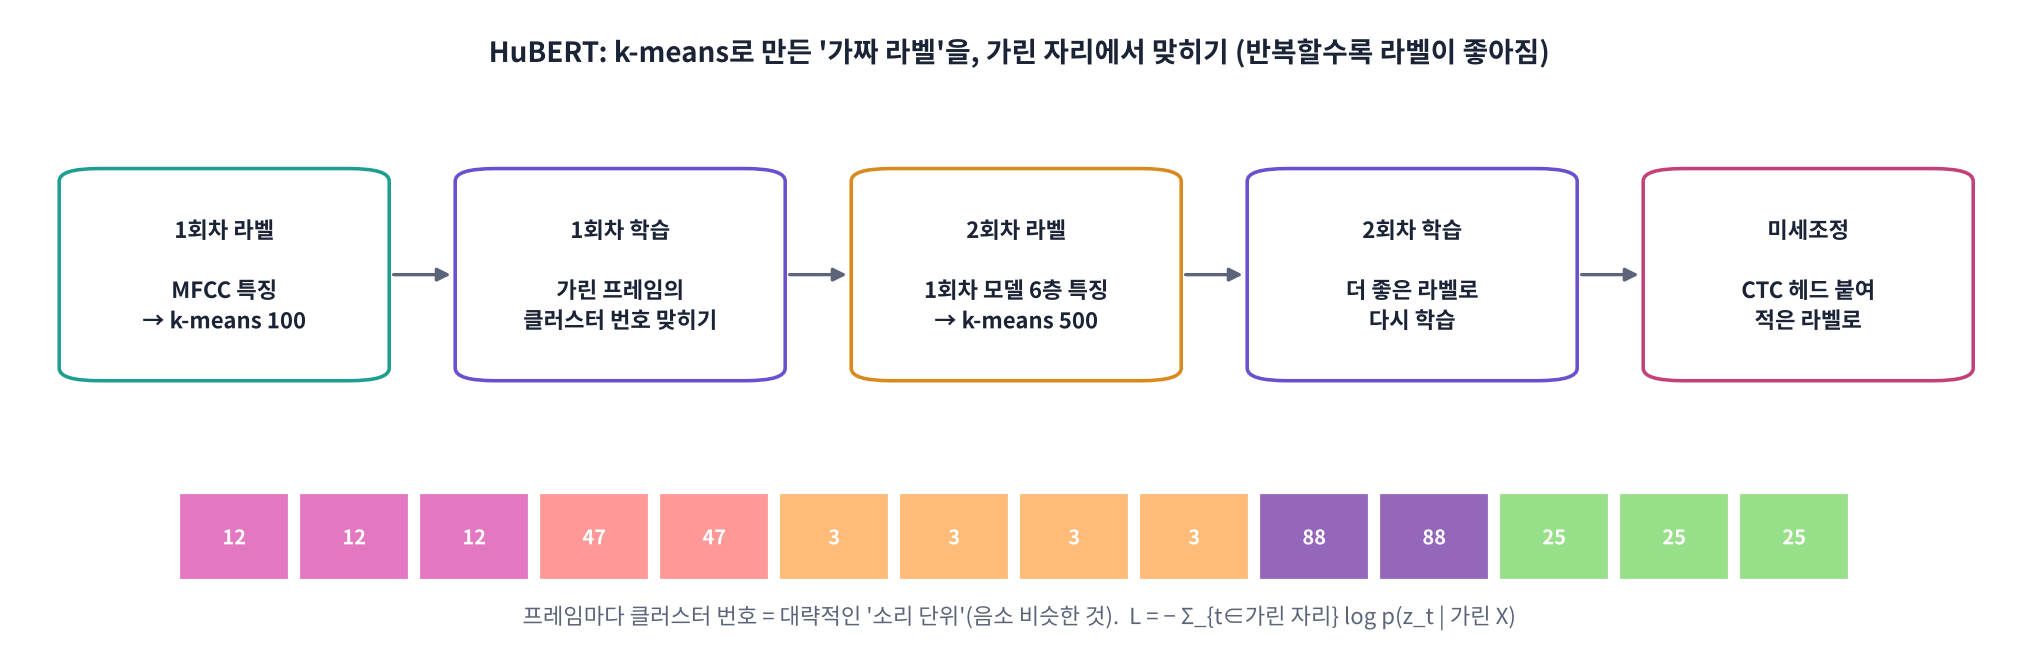

HuBERT(2021)는 대조 학습 대신 **가린 자리의 클러스터 번호 맞히기**(BERT의 가린 단어 맞히기와 같은 방식)를 합니다. 정답(가짜 라벨) $z_t$는 오프라인으로 만듭니다.

- **1회차**: MFCC 특징 → k-means(100개) → 프레임마다 클러스터 번호
- **2회차**: 1회차 모델의 6층 특징 → k-means(500개) → 더 좋은 번호로 다시 학습

$$
\mathcal{L} = -\sum_{t \in \mathcal{M}} \log p(z_t \mid \tilde X), \qquad \tilde X = \text{가린 입력}, \; \mathcal{M} = \text{가린 프레임 집합}
$$

**가린 자리만** 손실을 계산하므로, 모델은 앞뒤 문맥으로 "여기 무슨 소리가 있었을지"를 추론해야 합니다.

아래 실험: 같은 문장을 **목소리만 높여**(피치 +4 반음, 길이는 그대로) '다른 사람'처럼 만들고, 같은 프레임이 같은 클러스터로 가는지 비교합니다. 좋은 특징이라면 **목소리가 바뀌어도 같은 소리 → 같은 번호**여야 합니다.

In [ ]:
from transformers import HubertModel
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

HUB = "facebook/hubert-base-ls960"
hfe = Wav2Vec2FeatureExtractor.from_pretrained(HUB)
hubert = HubertModel.from_pretrained(HUB).to(DEVICE).eval()

y_shift = librosa.effects.pitch_shift(y_en, sr=SR, n_steps=4)          # '다른 화자' 흉내 (길이 그대로)
display(Audio(y_shift, rate=SR))

def mfcc_feats(y):          # HuBERT 1회차 특징: MFCC 13 + Δ + ΔΔ = 39차원, 창 400 · hop 320 → HuBERT와 같은 프레임 수
    m = librosa.feature.mfcc(y=y, sr=SR, n_mfcc=13, n_fft=400, hop_length=320, center=False)
    return np.vstack([m, librosa.feature.delta(m), librosa.feature.delta(m, order=2)]).T

def hubert_feats(y, layer=6):
    x = hfe(y, sampling_rate=SR, return_tensors="pt").input_values.to(DEVICE)
    with torch.no_grad():
        return hubert(x, output_hidden_states=True).hidden_states[layer][0].cpu().numpy()

def cluster_agreement(feat_fn, k=30):
    A, B = feat_fn(y_en), feat_fn(y_shift)
    n = min(len(A), len(B)); A, B = A[:n], B[:n]
    sc = StandardScaler().fit(np.vstack([A, B]))
    km = KMeans(k, n_init=4, random_state=0).fit(sc.transform(np.vstack([A, B])))
    la, lb = km.predict(sc.transform(A)), km.predict(sc.transform(B))
    return (la == lb).mean(), la, lb

res = {"MFCC (1st iteration)": cluster_agreement(mfcc_feats), "HuBERT layer 6": cluster_agreement(hubert_feats)}
fig, axs = plt.subplots(2, 1, figsize=(13, 3.6))
for ax, (name, (agr, la, lb)) in zip(axs, res.items()):
    ax.imshow(np.vstack([la, lb]), aspect="auto", cmap="tab20", interpolation="nearest")
    ax.set_yticks([0, 1]); ax.set_yticklabels(["original", "pitch +4"]); ax.set_title(f"{name}: same cluster on {agr:.0%} of frames")
axs[-1].set_xlabel("frame (20 ms)"); plt.tight_layout(); plt.show()
for name, (agr, la, _) in res.items():
    print(f"{name:22s}: 목소리를 바꿔도 같은 번호 {agr:.0%} | 같은 번호가 이어지는 평균 길이 {len(la) / (1 + np.sum(la[1:] != la[:-1])):.1f} 프레임")

보통 **HuBERT 6층 특징 쪽이 같은 번호 비율이 훨씬 높습니다.** MFCC는 목소리(피치 · 음색)가 바뀌면 값이 크게 달라지지만, 사전학습된 특징은 **'무슨 소리(음소)인가'** 를 더 많이 담고 **'누구 목소리인가'** 는 덜 담기 때문입니다. 이것이 HuBERT가 2회차에 MFCC 대신 자기 특징으로 라벨을 다시 만드는 이유이고, 이렇게 얻은 번호는 **음성 토큰**으로 TTS · Speech-to-Speech 모델에서도 쓰입니다(4주차 · 6주차).

| 모델 | 사전학습 목표 | 라벨 | 사전학습 데이터 (base) | 쓰임 |
|---|---|---|---|---|
| **wav2vec 2.0** | 가린 자리에서 진짜 양자화 코드 고르기 (대조) | 없음 | LibriSpeech 960 h | + CTC 미세조정 (Part 3), XLS-R(128개 언어) |
| **HuBERT** | 가린 자리의 k-means 번호 맞히기 (예측) | 없음 (가짜 라벨) | LibriSpeech 960 h | + CTC 미세조정, 음성 토큰 |
| **Whisper** | 받아쓰기 자체 (AED) | 인터넷 자막 68만 h (약한 지도) | — | 바로 받아쓰기 · 번역 (D7) |

#### 🔍 코드 해설: 자기지도 모델 다루기

| 코드 | 하는 일 |
|---|---|
| `Wav2Vec2ForPreTraining` | 양자화기 · 대조 손실을 포함한 **사전학습용** 모델. 미세조정 체크포인트(`-960h`)에는 양자화기가 없음 |
| `_get_feat_extract_output_lengths(L)` | 빈칸 3의 프레임 수 공식을 모델이 직접 계산 |
| `_compute_mask_indices(shape, mask_prob, mask_length)` | 가릴 프레임 표시 (bool). `mask_prob` ≈ $p \times M$ |
| `_sample_negative_indices(shape, 100, mask)` | 가린 프레임마다 같은 문장 안에서 가짜 후보 100개의 위치 |
| `out.projected_states` / `projected_quantized_states` | $c_t$, $q_t$를 같은 256차원으로 투영한 것 |
| `HubertModel(..., output_hidden_states=True)` | 층마다의 출력(0 = CNN 특징 투영, 1~12 = Transformer 층) |
| `KMeans(k).fit(...)` · `predict` | 프레임 특징 → 클러스터 번호 = HuBERT의 가짜 라벨 |

> ## 🎤 강사 스크립트 · Part 6-4 HuBERT 결과 읽기 · 4교시 워크시트  ⏱️ 12분
>
> 🎯 **HuBERT = k-means 번호를 가짜 정답으로. 좋은 특징은 목소리가 바뀌어도 같은 소리에 같은 번호를 준다.**
>
> 🗣️ "HuBERT는 '진짜 고르기' 대신 '번호 맞히기'입니다. 번호는 k-means로 만듭니다. 처음엔 MFCC로, 다음엔 1회차 모델의 특징으로 다시 만들면 번호가 점점 '소리 단위'에 가까워집니다."
>
> 🖥️ HuBERT 셀 결과: 위 줄(MFCC)과 아래 줄(HuBERT 6층)의 '같은 번호 비율'을 비교. ✅ 예상: MFCC 20~40%, HuBERT 6층 50~80% (문장 · 실행마다 다름).
>
> ⚠️ 드물게 차이가 작게 나오면: "k = 30, 문장 하나라 표본이 작아서 그렇습니다. 방향은 대체로 같습니다." 정도로 설명.
>
> 🖥️ [D6-9 ③](https://imguru-mooc.github.io/AI_Voice/day06/animation.html#ssl): MFCC로 k-means 한 걸음씩 → 화자별로 갈라짐(같은 번호 비율 낮음). HuBERT로 바꿔 다시 → 음소별로 모임(높음).
>
> 🗣️ "이 번호들은 '음성 토큰'으로 쓰여서, 4주차 TTS와 6주차 Speech-to-Speech 모델에서 다시 만납니다."
>
> 🖥️ 이어서 [worksheet.html 4교시 탭](https://imguru-mooc.github.io/AI_Voice/day06/worksheet.html) → 채점 → 제출 → 📋 캡처 → 노션 붙여 넣기.

---
### 📝 4교시 마무리: 개념 워크시트

> **[worksheet.html 열기 → 4교시 탭](https://imguru-mooc.github.io/AI_Voice/day06/worksheet.html)** — 사전학습 + 미세조정, 마스킹 $1-(1-p)^M$, 코드북 $320^2$, InfoNCE와 온도 κ, 가짜 후보 100개, HuBERT k-means 가짜 라벨, 가린 자리만 손실, wav2vec 2.0 · HuBERT · Whisper 비교
>
> 10문항을 풀고 **채점하기**를 누르세요. 결과 코드와 해설이 나옵니다. 채점 후에는 답이 잠깁니다. 4교시까지 마쳤다면 아래 Part 7의 **제출 방법**을 따라 노션에 제출하세요.

## Part 7. 정리 & 과제

### 오늘 배운 것
| 개념 | 핵심 | 수식 · 코드 |
|---|---|---|
| 정렬 문제 | 프레임 $T \gg$ 글자 $U$, 정렬 라벨 없음 | $\hat Y = \arg\max_Y P(Y \mid X)$ |
| CTC 접기 | 반복 합치기 → blank 지우기 | $\mathcal{B}(\texttt{hhe-ll-lloo}) = \texttt{hello}$ |
| CTC 확률 | 정답으로 접히는 경로를 모두 더함 | $\sum_{\pi \in \mathcal{B}^{-1}(Y)} \prod_t p_t(\pi_t)$ |
| 경로 수 | 연속 중복 없을 때 | $\binom{T+U}{2U}$ |
| forward α | 확장 라벨 $2U+1$, 두 칸 건너뛰기 조건 | $l'_s \ne \epsilon,\; l'_s \ne l'_{s-2}$ |
| Wav2Vec2 프레임 | 보폭 320 (20 ms), 수용 영역 400 (25 ms) | $T = \lfloor (L - 400)/320 \rfloor + 1$ |
| greedy 디코딩 | 프레임마다 argmax → 접기 | `logits.argmax(-1)` → `ctc_collapse` |
| 타임스탬프 | 스파이크 프레임 × 0.02 s | `t * S_TOT / SR` |
| AED | 연쇄 법칙, 한 토큰씩 | $\prod_u P(y_u \mid y_{<u}, X)$ |
| attention | 스케일 내적 | $\text{softmax}(QK^\top/\sqrt{d_k})V$ |
| Transducer | 격자: ∅ → 오른쪽, 글자 → 위 | $\alpha(t,u) = \alpha(t-1,u)\varnothing + \alpha(t,u-1) y$ |
| wav2vec 2.0 | 마스킹 · 양자화 · 대조 | $1-(1-p)^M \approx 0.49$, InfoNCE ($\kappa = 0.1$) |
| HuBERT | k-means 가짜 라벨 예측 | $-\sum_{t \in \mathcal{M}} \log p(z_t \mid \tilde X)$ |

### 📝 과제
1. **한국어 CTC 모델 써 보기**: `kresnik/wav2vec2-large-xlsr-korean`(XLS-R을 한국어로 CTC 미세조정한 모델)을 Part 3와 같은 코드로 불러, gTTS 한국어 문장 2개(`lang="ko"`)를 받아 적어 보세요. 어휘(`get_vocab()`)가 **음절인지 자모인지** 확인하고, 빈칸 4 · 5의 greedy 디코딩과 타임스탬프가 그대로 동작하는지 보고하세요.
2. **CTC 스파이크 측정**: 서로 다른 길이의 영어 문장 3개로 blank 비율과 '글자 한 개가 차지하는 프레임 수'를 표로 정리하세요. 말을 느리게(`gTTS(..., slow=True)`) 하면 무엇이 바뀌나요?
3. **설계 보고서 (반 페이지)**: "AI 콜센터에서 고객이 말하는 동안 실시간 자막을 띄우고, 통화가 끝나면 정확한 녹취록을 만든다." 실시간 자막과 최종 녹취록에 각각 CTC · AED · Transducer 중 무엇을 쓰겠습니까? 오늘의 비교표를 근거로 쓰세요.

### ✅ 개념 워크시트 제출
4교시 탭까지 모두 채점했다면 오늘 내용을 정리해 제출합니다.

> 📝 **[D6 개념 워크시트 열기](https://imguru-mooc.github.io/AI_Voice/day06/worksheet.html)** — 4교시 × 10문항 (객관식 5 · OX 2 · 선잇기 1 · 순서 맞추기 1 · 모두 고르기 1)

**제출 방법 (노션)**
1. 4개 교시 탭을 모두 채점합니다.
2. **제출** 버튼을 눌러 오답 정리를 엽니다.
3. **📋 캡처 (노션용 복사)**를 누른 뒤, 노션 제출 페이지에서 `Ctrl + V`로 붙여 넣습니다. 이름, 교시별 점수, 오답 표(내 답과 정답)가 함께 붙습니다.

> 🎬 복습용: [애니메이션 전체 보기](https://imguru-mooc.github.io/AI_Voice/day06/animation.html) — D6-1 ~ D6-9

### 다음 시간 (D7)
오늘은 Whisper를 **AED의 예**로만 잠깐 썼습니다. D7에서는 **Whisper를 깊게** 봅니다: 30초 창과 Log-Mel 입력, 모델 크기별 성능 · 속도, 언어 감지, 디코딩 옵션(빔 서치, temperature fallback), 그리고 오늘 본 한 토큰씩 생성 구조에서 생기는 **환각(hallucination)** 과 대응법입니다.

> ## 🎤 강사 스크립트 · Part 7 정리 · 과제 안내  ⏱️ 5분
>
> 🎯 **오늘의 한 줄: 정렬을 모르는 채 배우는 세 가지 방법(경로 합 · attention · 격자 경로 합)과, 라벨 없이 귀부터 트이게 하는 사전학습.**
>
> 🖥️ 슬라이드 p.18(수식 정리) → p.19(헷갈리기 쉬운 것) → p.20(체크리스트). 체크리스트를 학생들이 스스로 체크하게 합니다.
>
> 🗣️ (과제) "과제 1은 3주차 예습입니다. 한국어 모델은 어휘가 **음절**(약 2천 개)인지 **자모**인지에 따라 CTC 출력 모양이 달라집니다. `get_vocab()`으로 꼭 확인해 오세요. 과제 3은 정답이 하나가 아닙니다. 근거(스트리밍, 지연, 정확도)만 분명하면 됩니다."
>
> ➡️ "내일은 오늘 잠깐 만난 Whisper를 깊게 봅니다. 왜 환각이 생기는지, 어떻게 막는지까지."
>
> ⚠️ 노션 제출 확인: 이름 · 교시별 점수 · 오답 표가 붙었는지 한 명씩 확인.